<a href="https://colab.research.google.com/github/handdung/trash-classfication/blob/main/garbage_classification_hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ♻️ 제1회 빅데이터 프로그래밍 해커톤 — 쓰레기 이미지 분류 (12 클래스)

| 항목 | 내용 |
|---|---|
| 주제 | 쓰레기 이미지 12종 분류 (평가: 독립 테스트 데이터 **정확도**) |
| 기본 데이터 | Kaggle *Garbage Classification* (mostafaabla) — https://www.kaggle.com/datasets/mostafaabla/garbage-classification |
| 추가 데이터 | (사용 시 `EXTRA_DATA` 와 **참고문헌** 칸에 출처 기입) |
| 사용 패키지 | PyTorch (모델을 직접 설계), torchvision (데이터 변형만), NumPy, pandas, matplotlib, scikit-learn(분할·지표) — 사전학습 모델·YOLO 등 분류/탐지 패키지 **미사용** |
| 실행 환경 | Google Colab · T4 GPU |

### 노트북 구성

| 구분 | 내용 |
|---|---|
| **🔎 평가용 (맨 위)** | 학습된 모델을 GitHub 에서 내려받아 **재학습 없이** 독립 테스트 데이터의 정확도 계산 |
| 2장 데이터 준비 | 압축 해제, EDA, **중복·라벨 충돌 이미지 제거**, 층화 분할 |
| 4장 데이터 증강 | none / light / strong 정의·시각화 |
| 6장 실험 1 — 과적합 | 기본 CNN → Dropout / BatchNorm / 증강 / 결합 비교 |
| 7장 실험 2 — 하이퍼파라미터 | 학습률 · 배치 · 옵티마이저 · Dropout · 증강 강도 · 스케줄러 · 클래스 가중치 · 모델 크기 비교 (가점) |
| 8장 최종 CNN | 선택한 하이퍼파라미터 + 조기 종료, SEED 3개로 3번 학습 |
| 9장 최종 모델 선택 | 단일 모델 / 여러 모델 평균(앙상블) × 좌우반전 평균(TTA) 중 **검증 정확도가 가장 높은 조합을 자동 선택** → 평가 셀이 그대로 사용 |
| 10장 결과 요약 | 보고서용 표·그림 |

> 실험 설계 원칙(9주차): 한 번에 한 가지만 바꾸고 나머지는 고정, SEED 42, 시험(test) 데이터는 마지막 평가에서만 사용.

---
# 🔎 [평가용] 독립 테스트 데이터로 정확도 확인 — 재학습 없음

**평가 시 아래 셀 두 개만 실행하면 됩니다.** (아래쪽 학습 셀은 실행하지 않아도 됩니다)

1. `TEST_PATH` 에 테스트 데이터 경로(폴더 또는 zip)를 넣습니다. **비워두고 실행하면 업로드 창이 뜹니다.**
2. 실행하면 학습이 끝난 최종 모델(검증 정확도가 가장 높았던 조합)을 GitHub 에서 내려받아 예측하고, 정답 정보가 있으면 **정확도**를 출력합니다.

**정답은 아래 순서로 자동으로 찾습니다**

| 순서 | 정답 형태 | 예시 |
|---|---|---|
| ① | 정답 CSV (테스트 폴더 안 또는 `LABEL_CSV` 지정) | `file,label` / `파일명,정답` |
| ② | 클래스 이름 폴더 (대소문자·띄어쓰기·`_`·`-`·복수형·한글 허용) | `test/Brown Glass/a.jpg`, `test/신발/b.jpg` |
| ③ | 파일 이름 앞부분 | `battery12.jpg`, `white-glass_003.png` |
| — | 정답 없음 | 예측 CSV (`파일명, 예측 클래스, 확신도`) 저장 |

전처리는 학습 때와 똑같이 (회전 정보 반영 → RGB → 160×160 → 정규화) 적용됩니다.

In [ ]:
# ===================== 평가 설정 =====================
TEST_PATH = ''   # 테스트 폴더 또는 zip 경로 (예: '/content/test.zip'). 비워두면 업로드 창이 뜸
LABEL_CSV = ''   # (선택) 정답 CSV 경로. 비워두면 자동으로 찾음

# 학습된 모델 파일들과 best_setup.json 이 들어있는 GitHub 폴더 주소
MODEL_REPO = 'https://github.com/handdung/trash-classfication/tree/main/models/models'

내려받는 중: https://raw.githubusercontent.com/handdung/trash-classfication/main/models/models/best_setup.json
내려받는 중: https://raw.githubusercontent.com/handdung/trash-classfication/main/models/models/final_cnn_s42.pt
내려받는 중: https://raw.githubusercontent.com/handdung/trash-classfication/main/models/models/final_cnn_s2026.pt
내려받는 중: https://raw.githubusercontent.com/handdung/trash-classfication/main/models/models/final_aug_s42.pt
내려받는 중: https://raw.githubusercontent.com/handdung/trash-classfication/main/models/models/final_aug_s7.pt
내려받는 중: https://raw.githubusercontent.com/handdung/trash-classfication/main/models/models/final_aug_s2026.pt
✔ 최종 모델: final_cnn_s42.pt + final_cnn_s2026.pt + final_aug_s42.pt + final_aug_s7.pt + final_aug_s2026.pt | TTA: False | 학습 시 검증 정확도 0.9204
테스트 데이터를 업로드하세요 (zip 하나 또는 이미지 여러 장)


Saving synthetic_garbage_test.zip to synthetic_garbage_test.zip
✔ 테스트 이미지 601장
✔ 정답 확인: 600/601장 {'csv': 600}
   정답 CSV: labels.csv (파일 열: filepath, 정답 열: label)
✔ 예측 결과 저장: /content/independent_test_predictions.csv

   독립 테스트 정확도 (Accuracy): 0.3950   (237/600)
(정답을 알 수 없는 1장은 정확도 계산에서 제외)
              precision    recall  f1-score   support

     battery     0.2857    0.2000    0.2353        50
  biological     0.4545    0.2000    0.2778        50
 brown-glass     0.6667    0.5600    0.6087        50
   cardboard     0.4316    0.8200    0.5655        50
     clothes     0.3171    0.7800    0.4509        50
 green-glass     0.5510    0.5400    0.5455        50
       metal     0.1600    0.0800    0.1067        50
       paper     0.2609    0.1200    0.1644        50
     plastic     0.2821    0.2200    0.2472        50
       shoes     0.5682    0.5000    0.5319        50
       trash     0.2653    0.2600    0.2626        50
 white-glass     0.4259    0.4600    0.4423        50

    a

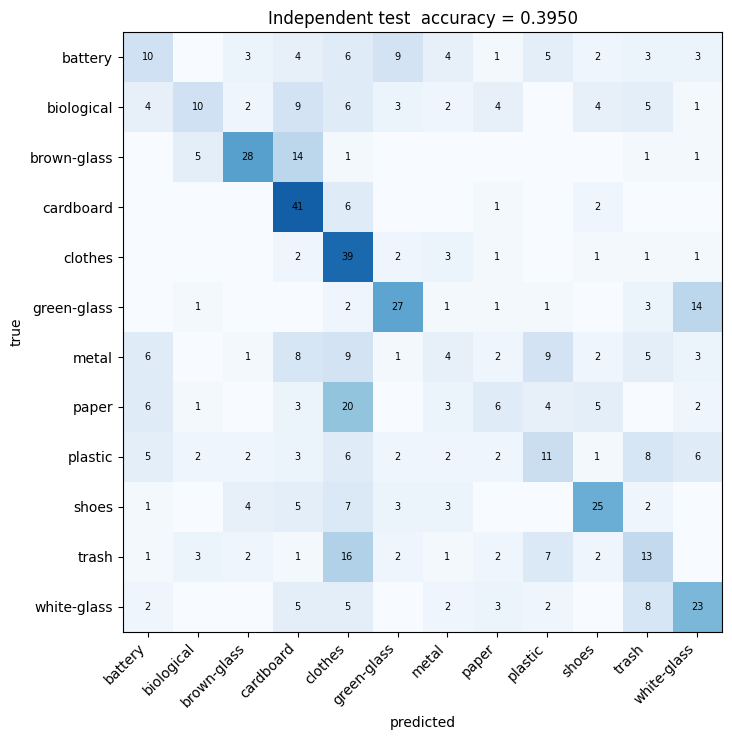

In [ ]:
import os, sys, re, json, glob, shutil, zipfile, urllib.request, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image, ImageFile, ImageOps
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings('ignore', category=UserWarning, module='PIL')

IN_COLAB = 'google.colab' in sys.modules
WORK = '/content' if os.path.isdir('/content') else os.path.abspath('.')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.gif', '.tif', '.tiff', '.jfif')

# ---------------- 모델 구조 (학습 노트북과 동일) ----------------
class GarbageCNN(nn.Module):
    def __init__(self, num_classes=12, use_bn=False, dropout=0.0, channels=(32, 64, 128, 256)):
        super().__init__()
        layers, in_c = [], 3
        for c in channels:
            for _ in range(2):
                layers.append(nn.Conv2d(in_c, c, 3, padding=1, bias=not use_bn))
                if use_bn:
                    layers.append(nn.BatchNorm2d(c))
                layers.append(nn.ReLU(inplace=True))
                in_c = c
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(4)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(in_c * 16, 256),
            nn.BatchNorm1d(256) if use_bn else nn.Identity(), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def build_arch(cfg, n):
    return GarbageCNN(n, cfg['use_bn'], cfg['dropout'], tuple(cfg['channels']))

def fetch(name):
    # MODEL_REPO 가 GitHub 주소면 내려받고, 로컬 폴더면 그대로 사용
    if '://' not in MODEL_REPO or '<' in MODEL_REPO:
        local = MODEL_REPO if ('<' not in MODEL_REPO and os.path.isdir(MODEL_REPO)) else '/content/drive/MyDrive/hackathon_results/models'
        if local.startswith('/content/drive') and IN_COLAB and not os.path.isdir('/content/drive/MyDrive'):
            from google.colab import drive; drive.mount('/content/drive')
        return os.path.join(local, name)
    base = MODEL_REPO.rstrip('/')
    m = re.match(r'https?://github\.com/([^/]+)/([^/]+)/(?:blob|tree)/(.+)', base)
    if m:
        base = f'https://raw.githubusercontent.com/{m.group(1)}/{m.group(2)}/{m.group(3)}'
    dst = os.path.join(WORK, 'downloaded_models', name)
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    if not os.path.exists(dst):
        print('내려받는 중:', f'{base}/{name}')
        urllib.request.urlretrieve(f'{base}/{name}', dst)
    return dst

with open(fetch('best_setup.json'), encoding='utf-8') as f:
    SETUP = json.load(f)
loaded = []
for name in SETUP['models']:
    ck = torch.load(fetch(name), map_location='cpu', weights_only=True)
    model = build_arch(ck['cfg'], len(ck['classes']))
    model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in ck['state_dict'].items()})
    loaded.append((model.to(device).eval(), ck))
CLASSES = loaded[0][1]['classes']
assert all(ck['classes'] == CLASSES for _, ck in loaded)
USE_TTA = SETUP['tta']
print(f"✔ 최종 모델: {' + '.join(SETUP['models'])} | TTA: {USE_TTA} | 학습 시 검증 정확도 {SETUP['val_acc']:.4f}")

# ---------------- 테스트 데이터 준비 ----------------
if not TEST_PATH:
    assert IN_COLAB, 'TEST_PATH 를 지정하세요.'
    from google.colab import files
    print('테스트 데이터를 업로드하세요 (zip 하나 또는 이미지 여러 장)')
    up_dir = os.path.join(WORK, 'uploaded_test'); os.makedirs(up_dir, exist_ok=True)
    for name, data in files.upload().items():
        with open(os.path.join(up_dir, name), 'wb') as f:
            f.write(data)
    zips = [f for f in os.listdir(up_dir) if f.lower().endswith('.zip')]
    TEST_PATH = os.path.join(up_dir, zips[0]) if len(zips) == 1 and len(os.listdir(up_dir)) == 1 else up_dir
if TEST_PATH.startswith('/content/drive') and IN_COLAB and not os.path.isdir('/content/drive/MyDrive'):
    from google.colab import drive; drive.mount('/content/drive')

def extract_zips(folder):
    for _ in range(3):
        zs = [os.path.join(d, f) for d, _, fs in os.walk(folder) for f in fs if f.lower().endswith('.zip')]
        if not zs:
            break
        for z in zs:
            with zipfile.ZipFile(z) as zf:
                zf.extractall(z[:-4] + '_unzipped')
            os.remove(z)

if os.path.isfile(TEST_PATH) and TEST_PATH.lower().endswith('.zip'):
    root = os.path.join(WORK, 'independent_test', os.path.splitext(os.path.basename(TEST_PATH))[0])
    shutil.rmtree(root, ignore_errors=True)
    with zipfile.ZipFile(TEST_PATH) as zf:
        zf.extractall(root)
    extract_zips(root)
elif os.path.isdir(TEST_PATH):
    root = TEST_PATH
    if any(f.lower().endswith('.zip') for _, _, fs in os.walk(root) for f in fs):
        copy = os.path.join(WORK, 'independent_test', os.path.basename(os.path.normpath(root)))
        shutil.rmtree(copy, ignore_errors=True)
        shutil.copytree(root, copy); extract_zips(copy); root = copy
else:
    raise FileNotFoundError(f'테스트 경로를 찾을 수 없습니다: {TEST_PATH}')

def hidden(path):
    return any(p.startswith(('.', '__MACOSX')) for p in os.path.relpath(path, root).split(os.sep))
files = sorted(os.path.join(d, f) for d, _, fs in os.walk(root) for f in fs
               if f.lower().endswith(IMG_EXT) and not hidden(os.path.join(d, f)))
assert files, f'{root} 에서 이미지를 찾지 못했습니다.'
print(f'✔ 테스트 이미지 {len(files)}장')

# ---------------- 정답 찾기 ----------------
ALIASES = {
    'battery':     ['batteries', '배터리', '건전지', '전지'],
    'biological':  ['bio', 'organic', 'food', 'foodwaste', 'compost', '음식물', '음식물쓰레기', '생물', '유기물'],
    'brown-glass': ['glassbrown', 'brownbottle', '갈색유리', '갈색병', '갈색유리병'],
    'cardboard':   ['carton', 'cardboards', 'box', '골판지', '종이박스', '박스', '상자'],
    'clothes':     ['clothing', 'cloth', 'textile', 'textiles', 'garment', '옷', '의류'],
    'green-glass': ['glassgreen', 'greenbottle', '초록유리', '녹색유리', '초록병', '녹색병'],
    'metal':       ['metals', 'can', 'cans', 'tin', '금속', '캔', '고철'],
    'paper':       ['papers', '종이'],
    'plastic':     ['plastics', '플라스틱', '페트', '페트병'],
    'shoes':       ['shoe', 'footwear', 'sneakers', '신발'],
    'trash':       ['general', 'generalwaste', 'other', 'others', 'residual', 'garbage', '일반쓰레기', '쓰레기', '기타'],
    'white-glass': ['glasswhite', 'clearglass', 'transparentglass', 'whitebottle', '투명유리', '흰유리', '백색유리', '투명병'],
}
def norm(s):
    return re.sub(r'[^0-9a-z가-힣]', '', str(s).lower())
LOOKUP = {norm(c): c for c in CLASSES}
for c, al in ALIASES.items():
    if c in CLASSES:
        for a in al:
            LOOKUP.setdefault(norm(a), c)
def to_class(s):
    n = norm(s)
    for k in (n, n[:-1] if n.endswith('s') else None, n + 's'):
        if k and k in LOOKUP:
            return LOOKUP[k]
    return None
def stem(p):
    return os.path.splitext(os.path.basename(str(p)))[0].lower()

csv_labels, csv_used = {}, None
csv_cands = [LABEL_CSV] if LABEL_CSV else sorted(glob.glob(os.path.join(root, '**', '*.csv'), recursive=True))
if not LABEL_CSV and os.path.isfile(TEST_PATH):
    csv_cands += sorted(glob.glob(os.path.join(os.path.dirname(TEST_PATH), '*.csv')))
img_stems = {stem(f) for f in files}
for cp in csv_cands:
    t = None
    for enc in ('utf-8-sig', 'cp949', 'latin-1'):
        try:
            t = pd.read_csv(cp, encoding=enc, dtype=str).dropna(how='all'); break
        except Exception:
            pass
    if t is None or t.shape[1] < 2:
        continue
    fcol = max(t.columns, key=lambda c: t[c].map(lambda v: stem(v) in img_stems).mean())
    if t[fcol].map(lambda v: stem(v) in img_stems).mean() < 0.5:
        continue
    lcol = max([c for c in t.columns if c != fcol], key=lambda c: t[c].map(lambda v: to_class(v) is not None).mean())
    if t[lcol].map(lambda v: to_class(v) is not None).mean() >= 0.8:
        csv_labels = {stem(f): to_class(l) for f, l in zip(t[fcol], t[lcol]) if to_class(l)}
        csv_used = f'{os.path.basename(cp)} (파일 열: {fcol}, 정답 열: {lcol})'
        break
    print(f'⚠️ {os.path.basename(cp)}: 정답 열을 클래스 이름으로 해석할 수 없어 사용하지 않음 (예: {t[lcol].head(3).tolist()})')

def label_of(f):
    if stem(f) in csv_labels:
        return csv_labels[stem(f)], 'csv'
    for d in reversed(os.path.relpath(os.path.dirname(f), root).split(os.sep)):
        d = d.replace('_unzipped', '')
        if d not in ('.', '') and to_class(d):
            return to_class(d), 'folder'
    prefix = re.sub(r'[\s_\-\.\(\)]*\d.*$', '', stem(f))
    if prefix and to_class(prefix):
        return to_class(prefix), 'filename'
    return None, None

labels, sources = zip(*[label_of(f) for f in files])
src_counts = pd.Series([s for s in sources if s]).value_counts().to_dict()
print(f'✔ 정답 확인: {sum(l is not None for l in labels)}/{len(files)}장', src_counts if src_counts else '(정답 정보 없음 → 예측만 저장)')
if csv_used:
    print('   정답 CSV:', csv_used)

# ---------------- 예측 ----------------
def preprocess(path, size, mean, std):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)
        arr = np.array(im.convert('RGB').resize((size, size), Image.BILINEAR), dtype=np.uint8)
    x = torch.from_numpy(arr).permute(2, 0, 1).float() / 255
    return (x - torch.tensor(mean).view(3, 1, 1)) / torch.tensor(std).view(3, 1, 1)
def safe_pre(args):
    try:
        return preprocess(*args)
    except Exception:
        return None

probs = np.zeros((len(files), len(CLASSES))); failed = set()
with torch.no_grad(), ThreadPoolExecutor(4) as ex:
    for model, ck in loaded:
        size, mean, std = ck['img_size'], ck['mean'], ck['std']
        for s in range(0, len(files), 64):
            idx = list(range(s, min(s + 64, len(files))))
            xs = list(ex.map(safe_pre, [(files[i], size, mean, std) for i in idx]))
            keep = [i for i, x in zip(idx, xs) if x is not None]
            failed |= {files[i] for i, x in zip(idx, xs) if x is None}
            if not keep:
                continue
            x = torch.stack([x for x in xs if x is not None]).to(device)
            p = torch.softmax(model(x).float(), 1)
            if USE_TTA:
                p = (p + torch.softmax(model(torch.flip(x, dims=[3])).float(), 1)) / 2
            probs[keep] += p.cpu().numpy() / len(loaded)
if failed:
    print(f'⚠️ 열 수 없는 파일 {len(failed)}개는 제외:', sorted(failed)[:5])

pred = probs.argmax(1)
out = pd.DataFrame({'file': [os.path.relpath(f, root) for f in files],
                    'pred': [CLASSES[i] for i in pred], 'confidence': probs.max(1).round(4),
                    'true': labels, 'label_source': sources})
out = out[[f not in failed for f in files]].reset_index(drop=True)
OUT_CSV = os.path.join(WORK, 'independent_test_predictions.csv')
out.to_csv(OUT_CSV, index=False, encoding='utf-8-sig')
print('✔ 예측 결과 저장:', OUT_CSV)

# ---------------- 정확도 ----------------
ev = out.dropna(subset=['true'])
if len(ev):
    acc = accuracy_score(ev['true'], ev['pred'])
    print('\n' + '=' * 50)
    print(f'   독립 테스트 정확도 (Accuracy): {acc:.4f}   ({(ev.true == ev.pred).sum()}/{len(ev)})')
    print('=' * 50)
    if len(ev) < len(out):
        print(f'(정답을 알 수 없는 {len(out) - len(ev)}장은 정확도 계산에서 제외)')
    present = [c for c in CLASSES if c in set(ev['true'])]
    print(classification_report(ev['true'], ev['pred'], labels=present, digits=4, zero_division=0))
    cm = confusion_matrix(ev['true'], ev['pred'], labels=CLASSES)
    fig, ax = plt.subplots(figsize=(9, 7.5))
    ax.imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'Independent test  accuracy = {acc:.4f}')
    plt.tight_layout(); plt.show()
else:
    print('\n정답 정보가 없어 정확도는 계산하지 않았습니다. 예측 결과:')
    display(out.head(20))
    print(out['pred'].value_counts().to_string())

---
# 📒 학습 과정 (해커톤 본 내용)

## 0. 실행 전 준비
1. **런타임 > 런타임 유형 변경 > T4 GPU**
2. `archive.zip` 을 구글 드라이브 **내 드라이브 최상단**에 업로드 (다른 위치면 `ZIP_PATH` 수정)
3. 처음엔 `QUICK_RUN = True` 로 끝까지 오류 없이 도는지 확인 → `False` 로 본 실험
4. **런타임 > 모두 실행** 대신, `1. 환경 설정` 셀부터 아래로 실행 (맨 위 평가용 셀은 학습 후에 사용)
5. 모든 실험 결과·모델은 드라이브 `hackathon_results/` 에 저장되어, **연결이 끊겨도 다시 실행하면 끝난 부분은 건너뜁니다.**

예상 소요 시간 (T4): 실험 1 약 40분 · 실험 2 약 55분 · 최종 CNN 3개 약 30분

## 1. 환경 설정

In [2]:
import os, sys, time, json, random, hashlib, zipfile, itertools, shutil
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, ImageOps
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU only')

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

torch 2.14.1+cu130 | device: cuda | Tesla T4


In [3]:
# ===================== 설정 =====================
QUICK_RUN = False          # True: 에폭을 크게 줄여 전체 코드가 도는지만 확인

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR, DRIVE_DIR = '/content', '/content/drive/MyDrive'
else:
    BASE_DIR = DRIVE_DIR = os.path.abspath('.')

ZIP_PATH    = f'{DRIVE_DIR}/archive.zip'
DATA_DIR    = f'{BASE_DIR}/garbage_data'
RESULTS_DIR = f'{DRIVE_DIR}/hackathon_results'
MODEL_DIR   = f'{RESULTS_DIR}/models'            # ← 평가용 모델이 저장되는 폴더
for d in ('runs', 'figures', 'models'):
    os.makedirs(f'{RESULTS_DIR}/{d}', exist_ok=True)

SEED        = 42
IMG_SIZE    = 160          # 모든 이미지를 160x160 으로 맞춤
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15
NUM_WORKERS = 2
USE_AMP     = device.type == 'cuda'

EPOCHS_EXP1  = 3 if QUICK_RUN else 25
EPOCHS_HP    = 2 if QUICK_RUN else 12
EPOCHS_FINAL = 3 if QUICK_RUN else 50
PATIENCE     = 8
FINAL_SEEDS  = [42, 7, 2026]   # 최종 모델을 SEED 만 바꿔 3번 학습 → 앙상블 후보
RETRAIN      = False       # True: 저장된 최종 모델이 있어도 다시 학습

# 추가 데이터 (선택): [(폴더 또는 zip 경로, '출처 문구'), ...]  — 폴더 안은 <클래스명>/이미지
EXTRA_DATA = []
CLASS_NAME_MAP = {}        # 추가 데이터 폴더명이 다를 때, 예) {'glass_brown': 'brown-glass'}

Mounted at /content/drive


## 2. 데이터 준비
### 2-1. 압축 해제와 이미지 목록

In [4]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def has_images(d):
    try:
        return any(f.lower().endswith(IMG_EXT) for f in os.listdir(d))
    except NotADirectoryError:
        return False

def find_class_root(base):
    for root, dirs, _ in os.walk(base):
        dirs[:] = sorted(d for d in dirs if not d.startswith(('.', '__')))
        if sum(has_images(os.path.join(root, d)) for d in dirs) >= 2:
            return root
    raise FileNotFoundError(f'{base} 아래에서 클래스 폴더를 찾지 못했습니다.')

def unzip_once(zip_path, dest):
    if not os.path.exists(dest):
        t = time.time()
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(dest)
        print(f'압축 해제: {os.path.basename(zip_path)} ({time.time()-t:.0f}s)')
    return dest

assert os.path.exists(ZIP_PATH) or os.path.exists(DATA_DIR), f'{ZIP_PATH} 가 없습니다.'
unzip_once(ZIP_PATH, DATA_DIR)
CLASS_ROOT = find_class_root(DATA_DIR)
CLASSES = sorted(d for d in os.listdir(CLASS_ROOT)
                 if not d.startswith(('.', '__')) and has_images(os.path.join(CLASS_ROOT, d)))
NUM_CLASSES = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
print(f'클래스 {NUM_CLASSES}개:', CLASSES)
assert NUM_CLASSES == 12, '클래스 수가 12가 아닙니다.'

def list_images(class_root, source, name_map=None):
    rows = []
    for d in sorted(os.listdir(class_root)):
        full = os.path.join(class_root, d)
        if not os.path.isdir(full):
            continue
        cls = (name_map or {}).get(d, d)
        if cls not in CLS2IDX:
            print(f'  [건너뜀] {source}: 폴더 {d} 는 12개 클래스에 없음')
            continue
        for dp, _, fs in os.walk(full):
            rows += [(os.path.join(dp, f), cls, source) for f in sorted(fs) if f.lower().endswith(IMG_EXT)]
    return rows

rows = list_images(CLASS_ROOT, 'kaggle_garbage')
for i, (path, src) in enumerate(EXTRA_DATA):
    if path.lower().endswith('.zip'):
        path = unzip_once(path, f'{BASE_DIR}/extra_{i}')
    rows += list_images(find_class_root(path), src, CLASS_NAME_MAP)

df = pd.DataFrame(rows, columns=['path', 'label', 'source'])
print('전체 이미지 수:', len(df))
display(df.groupby(['source', 'label']).size().unstack(0).fillna(0).astype(int))

압축 해제: archive.zip (8s)
클래스 12개: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
전체 이미지 수: 15515


source,kaggle_garbage
label,
battery,945
biological,985
brown-glass,607
cardboard,891
clothes,5325
green-glass,629
metal,769
paper,1050
plastic,865


### 2-2. 데이터 정제 — 중복 이미지와 라벨 충돌 제거
데이터를 점검한 결과 **완전히 같은 이미지가 18쌍** 있었고, 그중 **3쌍은 서로 다른 클래스**에 들어 있었습니다(라벨 오류).
- 서로 다른 클래스에 있는 같은 이미지 → 정답을 알 수 없으므로 **모두 제거**
- 같은 클래스 안의 중복 → **한 장만 남김** (학습/시험에 동시에 들어가 점수가 부풀려지는 것 방지)
- 추가 데이터가 기본 데이터와 겹치면 추가 데이터 쪽을 제거

In [5]:
def md5_of(p):
    with open(p, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
with ThreadPoolExecutor(8) as ex:
    df['md5'] = list(ex.map(md5_of, df.path))

n0 = len(df)
nlab = df.groupby('md5')['label'].nunique()
conflict = df[df.md5.isin(nlab[nlab > 1].index)]
df = df[~df.md5.isin(nlab[nlab > 1].index)]
n1 = len(df)
df = df.drop_duplicates('md5', keep='first').reset_index(drop=True)
df['y'] = df['label'].map(CLS2IDX)
print(f'라벨 충돌 이미지 제거: {n0 - n1}장  /  같은 클래스 중복 제거: {n1 - len(df)}장  →  남은 이미지 {len(df)}장')
if len(conflict):
    display(conflict[['path', 'label']].assign(path=lambda d: d.path.map(os.path.basename)).sort_values('path'))

라벨 충돌 이미지 제거: 6장  /  같은 클래스 중복 제거: 16장  →  남은 이미지 15493장


,path,label
9781,metal459.jpg,metal
11267,plastic159.jpg,plastic
11708,plastic556.jpg,plastic
14773,white-glass129.jpg,white-glass
15088,white-glass412.jpg,white-glass
15475,white-glass761.jpg,white-glass


### 2-3. 탐색적 데이터 분석 (EDA)

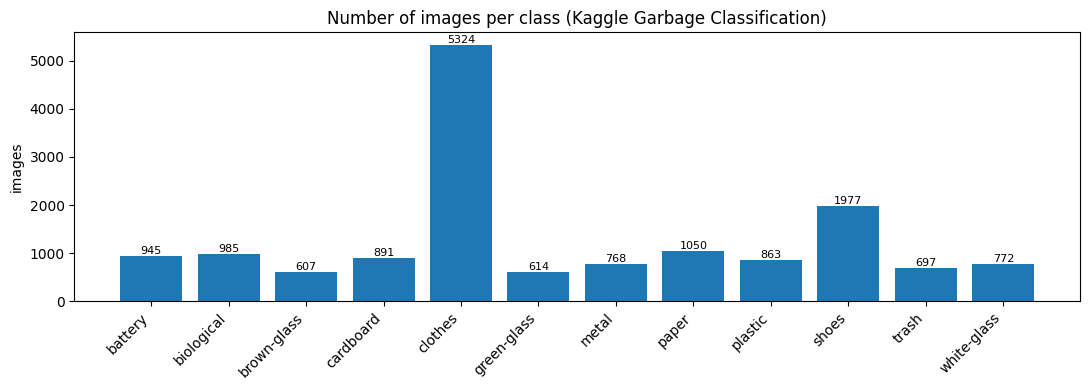

최다/최소 클래스 비율: 8.8배 → 클래스 불균형. 분할은 층화추출로 진행
원본 크기 — 가로 중앙값 400 (139~865), 세로 중앙값 384 (120~823)


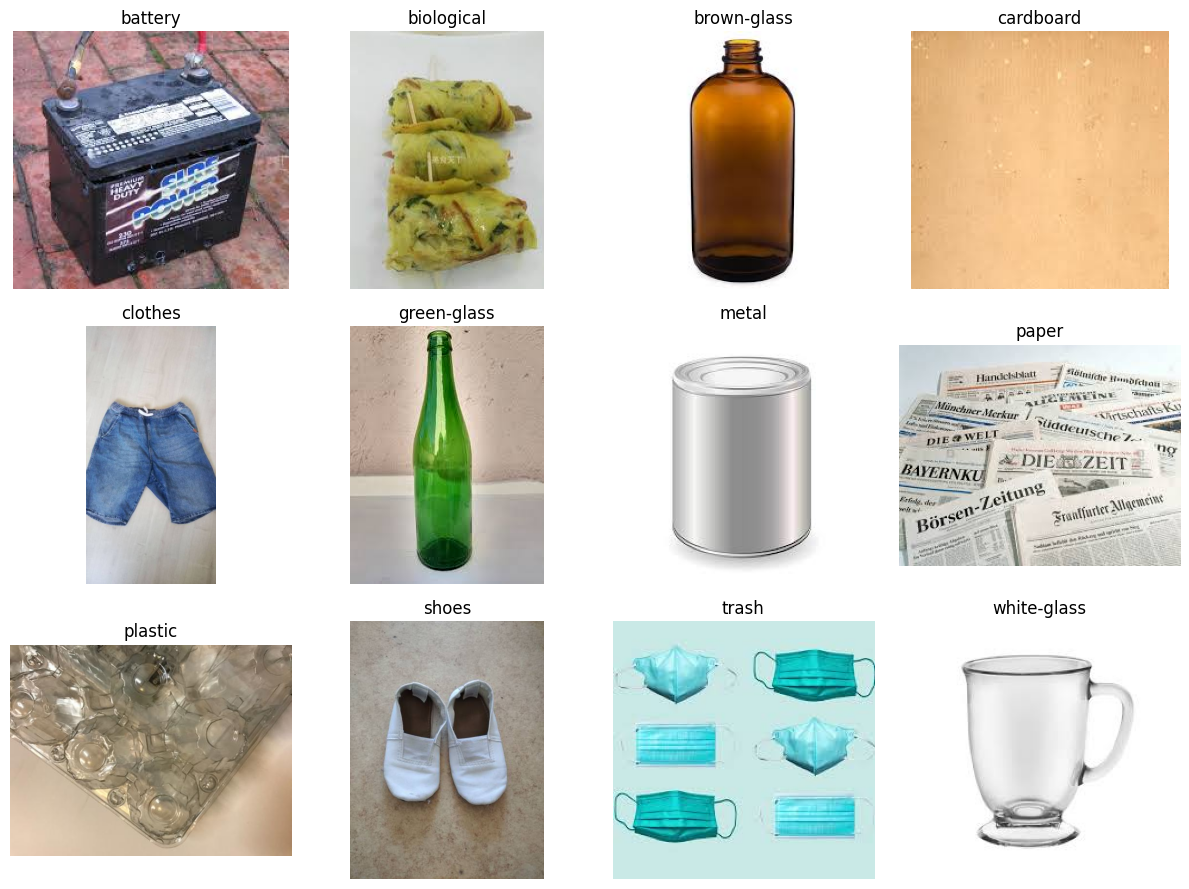

In [6]:
counts = df[df.source == 'kaggle_garbage']['label'].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(CLASSES, counts.values, color='tab:blue'); ax.bar_label(bars, fontsize=8)
ax.set_title('Number of images per class (Kaggle Garbage Classification)'); ax.set_ylabel('images')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/01_class_distribution.png', dpi=150); plt.show()
print(f'최다/최소 클래스 비율: {counts.max()/counts.min():.1f}배 → 클래스 불균형. 분할은 층화추출로 진행')

sample = df.sample(min(600, len(df)), random_state=SEED)
w, h = np.array([Image.open(p).size for p in sample.path]).T
print(f'원본 크기 — 가로 중앙값 {np.median(w):.0f} ({w.min()}~{w.max()}), 세로 중앙값 {np.median(h):.0f} ({h.min()}~{h.max()})')

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, c in zip(axes.flat, CLASSES):
    ax.imshow(Image.open(df[df.label == c].sample(1, random_state=SEED).path.iloc[0]).convert('RGB'))
    ax.set_title(c); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/02_samples.png', dpi=120); plt.show()

### 2-4. 학습 / 검증 / 시험 분할 (70 / 15 / 15, 층화추출)
시험 세트는 **기본 Kaggle 데이터에서만** 뽑고, 추가 데이터는 **학습 세트에만** 넣습니다.

In [7]:
base_df, extra_df = df[df.source == 'kaggle_garbage'], df[df.source != 'kaggle_garbage']
trval_df, test_df = train_test_split(base_df, test_size=TEST_RATIO, stratify=base_df.y, random_state=SEED)
train_df, val_df = train_test_split(trval_df, test_size=VAL_RATIO / (1 - TEST_RATIO), stratify=trval_df.y, random_state=SEED)
train_df = pd.concat([train_df, extra_df])
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

split_table = pd.DataFrame({'train': train_df.label.value_counts(), 'val': val_df.label.value_counts(),
                            'test': test_df.label.value_counts()}).reindex(CLASSES).fillna(0).astype(int)
split_table.loc['TOTAL'] = split_table.sum()
display(split_table); split_table.to_csv(f'{RESULTS_DIR}/split_table.csv')

,train,val,test
label,,,
battery,661,142,142
biological,689,148,148
brown-glass,425,91,91
cardboard,623,134,134
clothes,3727,798,799
green-glass,430,92,92
metal,538,115,115
paper,735,158,157
plastic,605,129,129


### 2-5. 이미지를 미리 줄여 메모리에 올리기 (캐싱)
jpg 를 매 에폭 다시 읽으면 디스크·CPU 가 병목이 되므로, 크기별로 한 번만 줄여 **uint8 텐서**로 보관합니다.
(약 1.2GB RAM)

In [8]:
def load_resized(path, size):
    try:
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im)        # 휴대폰 사진 회전 정보 반영 (평가 셀과 같은 전처리)
            return np.asarray(im.convert('RGB').resize((size, size), Image.BILINEAR), dtype=np.uint8)
    except Exception as e:
        print('읽기 실패:', path, e)
        return np.zeros((size, size, 3), np.uint8)

def build_cache(paths, size):
    arr = np.empty((len(paths), size, size, 3), np.uint8)
    with ThreadPoolExecutor(8) as ex:
        for i, a in enumerate(ex.map(lambda p: load_resized(p, size), paths)):
            arr[i] = a
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()

CACHE = {}
def get_cache(size):
    if size not in CACHE:
        t = time.time()
        CACHE[size] = tuple(build_cache(d.path.tolist(), size) for d in (train_df, val_df, test_df))
        print(f'{size}px 캐시 생성 {time.time()-t:.0f}s |', [tuple(x.shape) for x in CACHE[size]])
    return CACHE[size]

X_train, X_val, X_test = get_cache(IMG_SIZE)
y_train, y_val, y_test = (torch.tensor(d.y.values) for d in (train_df, val_df, test_df))

def channel_stats(X, bs=512):
    s = torch.zeros(3, dtype=torch.float64); ss = torch.zeros(3, dtype=torch.float64); n = 0
    for i in range(0, len(X), bs):
        b = X[i:i+bs].double() / 255
        s += b.sum((0, 2, 3)); ss += (b ** 2).sum((0, 2, 3)); n += b.shape[0] * b.shape[2] * b.shape[3]
    m = s / n
    return m.tolist(), (ss / n - m ** 2).sqrt().tolist()

DATA_MEAN, DATA_STD = channel_stats(X_train)          # 학습 데이터로만 계산
print('정규화 mean', np.round(DATA_MEAN, 3), 'std', np.round(DATA_STD, 3))

160px 캐시 생성 32s | [(10845, 3, 160, 160), (2324, 3, 160, 160), (2324, 3, 160, 160)]
정규화 mean [0.658 0.616 0.586] std [0.278 0.29  0.303]


## 3. Dataset

In [9]:
class TensorImageDataset(Dataset):
    def __init__(self, X, y, transform):
        self.X, self.y, self.transform = X, y, transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.transform(self.X[i]), self.y[i]

## 4. 데이터 증강

| 강도 | 변형 | 사용처 |
|---|---|---|
| `none` | 없음 | 비교 기준 |
| `light` | 회전 ±15°, 좌우 반전, 확대·축소, 위치 이동 (9주차 4가지) | CNN 실험 |
| `strong` | light + 무작위 자르기(확대), 상하 반전, 밝기·대비 | 촬영 거리·조명이 다른 사진에 대비 |

**데이터에 맞는 변형 고르기:** `brown / green / white-glass` 는 **색으로 구분**되므로 색상(hue)을 바꾸는 변형은 쓰지 않습니다.
증강은 학습 데이터에만 적용합니다.

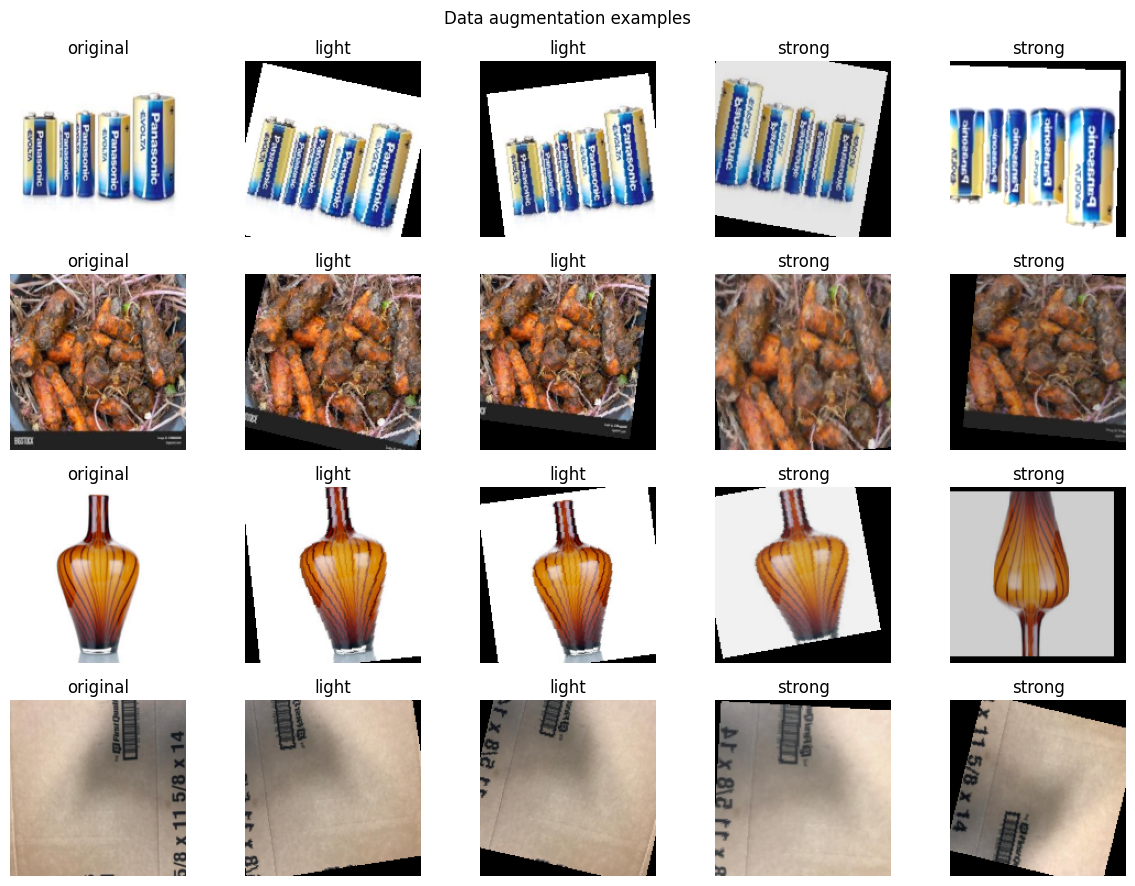

In [10]:
def make_transform(aug='none', mean=None, std=None, size=IMG_SIZE):
    ops = []
    if aug in ('light', 'strong'):
        ops += [v2.RandomHorizontalFlip(), v2.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1))]
    if aug == 'strong':
        ops = [v2.RandomResizedCrop(size, scale=(0.7, 1.0), antialias=True), v2.RandomVerticalFlip(p=0.2),
               v2.ColorJitter(brightness=0.2, contrast=0.2)] + ops
    ops += [v2.ToDtype(torch.float32, scale=True)]
    if mean is not None:
        ops += [v2.Normalize(mean, std)]
    return v2.Compose(ops)

set_seed(SEED)
idx = [int(np.where(y_train.numpy() == c)[0][0]) for c in range(4)]
fig, axes = plt.subplots(4, 5, figsize=(12, 9))
for r, i in enumerate(idx):
    axes[r, 0].imshow(X_train[i].permute(1, 2, 0)); axes[r, 0].set_title('original')
    for c, aug in enumerate(['light', 'light', 'strong', 'strong'], 1):
        axes[r, c].imshow(make_transform(aug)(X_train[i]).permute(1, 2, 0).clamp(0, 1)); axes[r, c].set_title(aug)
    for a in axes[r]: a.axis('off')
plt.suptitle('Data augmentation examples'); plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/03_augmentation.png', dpi=120); plt.show()

## 5. 모델과 학습 함수
`Conv→(BatchNorm)→ReLU` 를 두 번 쌓고 `MaxPool` 로 크기를 절반으로 줄이는 블록 4개 (160→80→40→20→10) + 완전연결층 2개.
`use_bn`, `dropout`, `channels`(필터 수) 를 설정으로 바꿀 수 있게 만들어 **한 가지씩만 바꿔 비교**합니다.

In [11]:
class GarbageCNN(nn.Module):
    def __init__(self, num_classes=12, use_bn=False, dropout=0.0, channels=(32, 64, 128, 256)):
        super().__init__()
        layers, in_c = [], 3
        for c in channels:
            for _ in range(2):
                layers.append(nn.Conv2d(in_c, c, 3, padding=1, bias=not use_bn))
                if use_bn:
                    layers.append(nn.BatchNorm2d(c))
                layers.append(nn.ReLU(inplace=True))
                in_c = c
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(4)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(in_c * 16, 256),
            nn.BatchNorm1d(256) if use_bn else nn.Identity(), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def build_model(cfg):
    return GarbageCNN(NUM_CLASSES, cfg['use_bn'], cfg['dropout'], tuple(cfg['channels']))

m = build_model({'use_bn': True, 'dropout': 0.5, 'channels': [32, 64, 128, 256]})
print(f'CNN 파라미터 수: {sum(p.numel() for p in m.parameters()):,} | 출력', m(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)).shape)

CNN 파라미터 수: 2,225,644 | 출력 torch.Size([2, 12])


In [12]:
BASE_CFG = dict(model='cnn', img_size=IMG_SIZE, channels=[32, 64, 128, 256], use_bn=True, dropout=0.5,
                aug='light', optimizer='Adam', lr=1e-3, weight_decay=0.0, batch_size=64,
                scheduler='none', class_weight=False)

def make_loaders(cfg):
    Xtr, Xva, _ = get_cache(cfg['img_size'])
    mean, std = DATA_MEAN, DATA_STD
    kw = dict(num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda', persistent_workers=NUM_WORKERS > 0)
    return (DataLoader(TensorImageDataset(Xtr, y_train, make_transform(cfg['aug'], mean, std, cfg['img_size'])),
                       cfg['batch_size'], shuffle=True, drop_last=True, **kw),
            DataLoader(TensorImageDataset(Xva, y_val, make_transform('none', mean, std)), 128, shuffle=False, **kw))

def make_optimizer(cfg, model):
    params = model.parameters()
    o, lr, wd = cfg['optimizer'], cfg['lr'], cfg['weight_decay']
    if o == 'SGD':   return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    if o == 'Adam':  return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if o == 'AdamW': return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(o)

def make_scheduler(cfg, opt, epochs):
    s = cfg['scheduler']
    if s == 'cosine':  return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    if s == 'plateau': return torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    return None

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
                loss = criterion(out.float(), y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
            tot_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return tot_loss / n, correct / n

def train_model(cfg, epochs, early_stop=None, verbose=True, seed=SEED):
    set_seed(seed)
    model = build_model(cfg).to(device)
    train_loader, val_loader = make_loaders(cfg)
    weight = None
    if cfg['class_weight']:
        cnt = torch.bincount(y_train, minlength=NUM_CLASSES).float()
        weight = (cnt.sum() / (NUM_CLASSES * cnt)).to(device)
    criterion = nn.CrossEntropyLoss(weight=weight)
    eval_criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(cfg, model)
    scheduler = make_scheduler(cfg, optimizer, epochs)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr']}
    best = dict(val_acc=-1, epoch=0, state=None)
    best_vloss, bad, t0 = float('inf'), 0, time.time()
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer, scaler)
        vl, va = run_epoch(model, val_loader, eval_criterion)
        for k, v in zip(hist, (tl, ta, vl, va, optimizer.param_groups[0]['lr'])):
            hist[k].append(v)
        if scheduler is not None:
            scheduler.step(vl) if cfg['scheduler'] == 'plateau' else scheduler.step()
        if va > best['val_acc']:          # 검증 정확도가 가장 높은 시점의 가중치 보관
            best = dict(val_acc=va, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        if verbose:
            print(f'  ep {ep:3d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:5.0f}s')
        if early_stop:
            if vl < best_vloss - 1e-4: best_vloss, bad = vl, 0
            else:
                bad += 1
                if bad >= early_stop:
                    print(f'  ⏹ 조기 종료 (ep {ep}): {early_stop} 에폭 동안 검증 손실 개선 없음'); break
    summary = dict(best_val_acc=best['val_acc'], best_epoch=best['epoch'],
                   final_train_acc=hist['train_acc'][-1], final_val_acc=hist['val_acc'][-1],
                   gap_train_val=hist['train_acc'][-1] - hist['val_acc'][-1],
                   min_val_loss=min(hist['val_loss']), final_val_loss=hist['val_loss'][-1],
                   val_loss_rise=hist['val_loss'][-1] - min(hist['val_loss']),
                   epochs_run=len(hist['val_acc']), time_sec=time.time() - t0,
                   params=sum(p.numel() for p in model.parameters()))
    model.load_state_dict(best['state'])
    return model, summary, hist

def run_cached(name, overrides, epochs, early_stop=None):
    cfg = {**BASE_CFG, **overrides}
    key = hashlib.md5(json.dumps([cfg, epochs, early_stop, SEED, len(y_train)], sort_keys=True).encode()).hexdigest()[:10]
    path = f'{RESULTS_DIR}/runs/{key}.json'
    if os.path.exists(path):
        with open(path) as f: r = json.load(f)
        print(f'✔ [{name}] 저장된 결과 사용 (best val acc {r["summary"]["best_val_acc"]:.4f})')
        return {**r, 'name': name}
    print(f'▶ [{name}] 학습: { {k: v for k, v in cfg.items() if BASE_CFG.get(k) != v} or "기본 설정"}')
    _, summary, hist = train_model(cfg, epochs, early_stop)
    r = dict(name=name, cfg=cfg, summary=summary, hist=hist)
    with open(path, 'w') as f: json.dump(r, f)
    return r

# ---- 최종 모델 저장/불러오기 (평가 셀이 읽는 형식) ----
def save_final(model, cfg, name, hist=None):
    # 반정밀도(fp16)로 저장 → 파일 크기 절반 (GitHub 웹 업로드 25MB 제한 대비), 정확도 차이 없음
    sd = {k: (v.half() if v.is_floating_point() else v).cpu() for k, v in model.state_dict().items()}
    torch.save({'state_dict': sd, 'cfg': cfg, 'classes': CLASSES, 'img_size': cfg['img_size'],
                'mean': DATA_MEAN, 'std': DATA_STD}, f'{MODEL_DIR}/{name}.pt')
    if hist is not None:
        with open(f'{RESULTS_DIR}/runs/final_{name}_hist.json', 'w') as f: json.dump(hist, f)
    print(f'💾 저장: {MODEL_DIR}/{name}.pt ({os.path.getsize(f"{MODEL_DIR}/{name}.pt")/1e6:.1f} MB)')

def load_final(name):
    ck = torch.load(f'{MODEL_DIR}/{name}.pt', map_location='cpu', weights_only=True)
    model = build_model(ck['cfg'])
    model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in ck['state_dict'].items()})
    hp = f'{RESULTS_DIR}/runs/final_{name}_hist.json'
    hist = json.load(open(hp)) if os.path.exists(hp) else None
    print(f'✔ 저장된 모델 사용: {name}')
    return model.to(device).eval(), ck['cfg'], hist

In [13]:
def summary_table(results):
    t = pd.DataFrame([{'experiment': r['name'], **r['summary']} for r in results]).set_index('experiment')
    return t[['best_val_acc', 'best_epoch', 'final_train_acc', 'final_val_acc', 'gap_train_val',
              'min_val_loss', 'final_val_loss', 'val_loss_rise', 'epochs_run', 'time_sec']].round(4)

def plot_curves(results, fname, title):
    n = len(results)
    fig, axes = plt.subplots(2, n, figsize=(3.6 * max(n, 2), 6), squeeze=False)
    for j, r in enumerate(results):
        h = r['hist']; ep = range(1, len(h['val_loss']) + 1)
        axes[0, j].plot(ep, h['train_loss'], '--', label='train'); axes[0, j].plot(ep, h['val_loss'], label='val')
        axes[1, j].plot(ep, h['train_acc'], '--', label='train');  axes[1, j].plot(ep, h['val_acc'], label='val')
        axes[0, j].axvline(int(np.argmin(h['val_loss'])) + 1, color='gray', ls=':', lw=1)
        axes[0, j].set_title(r['name']); axes[0, j].set_ylabel('loss'); axes[1, j].set_ylabel('accuracy')
        axes[1, j].set_xlabel('epoch'); axes[0, j].legend(); axes[1, j].legend()
    for j in range(n, axes.shape[1]):
        axes[0, j].axis('off'); axes[1, j].axis('off')
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/{fname}', dpi=130); plt.show()

def plot_group(results, group, fname):
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 3.8))
    for r in results:
        a1.plot(range(1, len(r['hist']['val_acc']) + 1), r['hist']['val_acc'], marker='.', label=r['name'])
        a2.plot(range(1, len(r['hist']['val_loss']) + 1), r['hist']['val_loss'], marker='.', label=r['name'])
    a1.set_title(f'[{group}] validation accuracy'); a1.set_xlabel('epoch'); a1.legend(fontsize=8)
    a2.set_title(f'[{group}] validation loss'); a2.set_xlabel('epoch'); a2.legend(fontsize=8)
    names = [r['name'] for r in results]; accs = [r['summary']['best_val_acc'] for r in results]
    bars = a3.bar(names, accs, color=['tab:orange' if a == max(accs) else 'tab:gray' for a in accs])
    a3.bar_label(bars, fmt='%.3f', fontsize=8); a3.set_ylim(min(accs) - 0.05, min(1, max(accs) + 0.03))
    a3.set_title(f'[{group}] best val accuracy'); a3.tick_params(axis='x', rotation=20)
    plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/{fname}', dpi=130); plt.show()

## 6. 실험 1 — 과적합 확인과 해결

| 이름 | BatchNorm | Dropout | 증강 | 고정 조건 |
|---|---|---|---|---|
| A_base | ✗ | 0 | none | Adam · LR 1e-3 · BATCH 64 · SEED 42 · 25 에폭 |
| B_dropout | ✗ | 0.5 | none | 〃 |
| C_batchnorm | ✓ | 0 | none | 〃 |
| D_augment | ✗ | 0 | light | 〃 |
| E_all | ✓ | 0.5 | light | 〃 |

과적합을 눈으로 보기 위해 이 실험에서는 조기 종료를 쓰지 않습니다.

In [14]:
EXP1 = {
    'A_base':      dict(use_bn=False, dropout=0.0, aug='none'),
    'B_dropout':   dict(use_bn=False, dropout=0.5, aug='none'),
    'C_batchnorm': dict(use_bn=True,  dropout=0.0, aug='none'),
    'D_augment':   dict(use_bn=False, dropout=0.0, aug='light'),
    'E_all':       dict(use_bn=True,  dropout=0.5, aug='light'),
}
exp1 = [run_cached(name, ov, EPOCHS_EXP1) for name, ov in EXP1.items()]

✔ [A_base] 저장된 결과 사용 (best val acc 0.7810)
✔ [B_dropout] 저장된 결과 사용 (best val acc 0.8081)
✔ [C_batchnorm] 저장된 결과 사용 (best val acc 0.8520)
✔ [D_augment] 저장된 결과 사용 (best val acc 0.8188)
✔ [E_all] 저장된 결과 사용 (best val acc 0.8464)


,best_val_acc,best_epoch,final_train_acc,final_val_acc,gap_train_val,min_val_loss,final_val_loss,val_loss_rise,epochs_run,time_sec
experiment,,,,,,,,,,
A_base,0.7810,11,0.9712,0.7788,0.1923,0.7456,1.2648,0.5192,25,366.1363
B_dropout,0.8081,22,0.8630,0.8029,0.0601,0.6314,0.6576,0.0262,25,368.3910
C_batchnorm,0.8520,25,0.9906,0.8520,0.1386,0.5341,0.5758,0.0417,25,427.6901
D_augment,0.8188,21,0.8584,0.8158,0.0425,0.6068,0.6135,0.0067,25,539.3622
E_all,0.8464,24,0.8425,0.8434,-0.0009,0.4661,0.4760,0.0099,25,587.0381


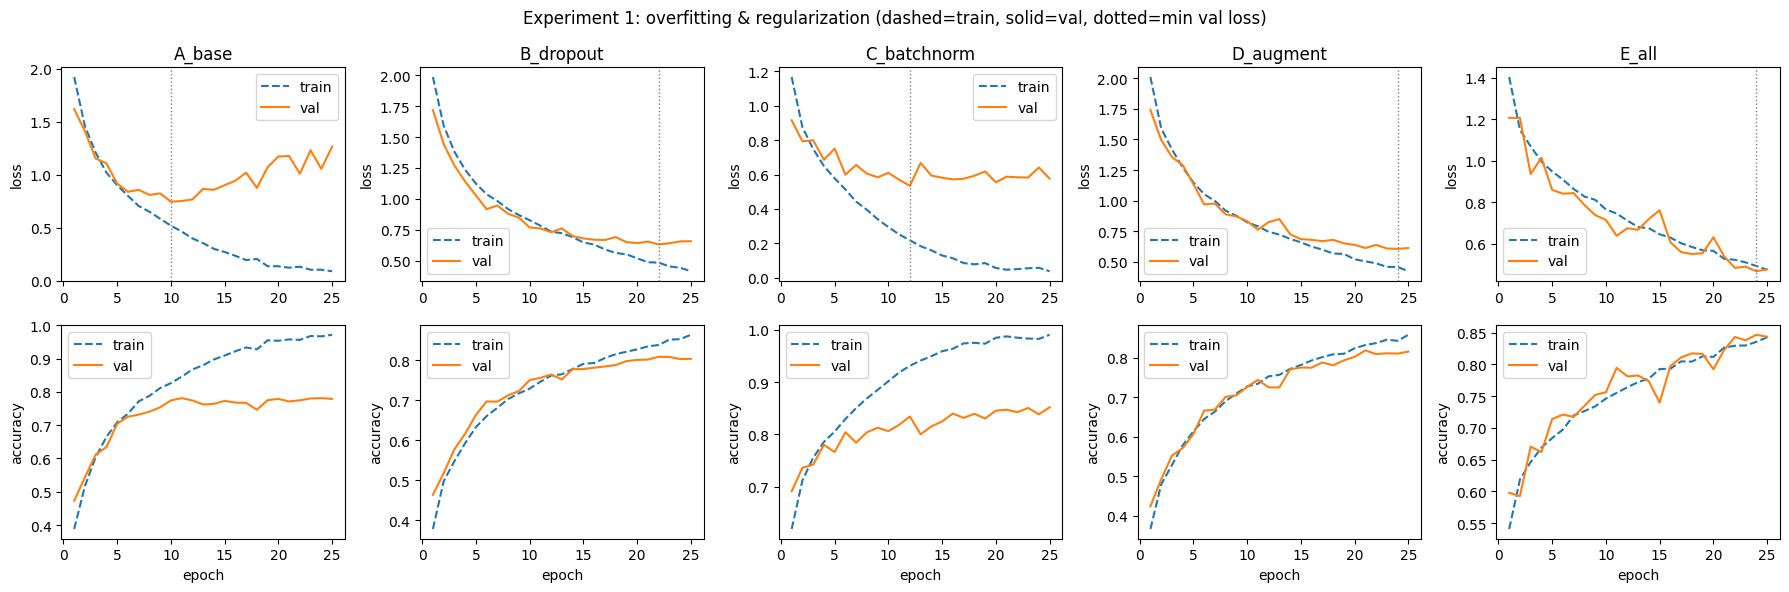

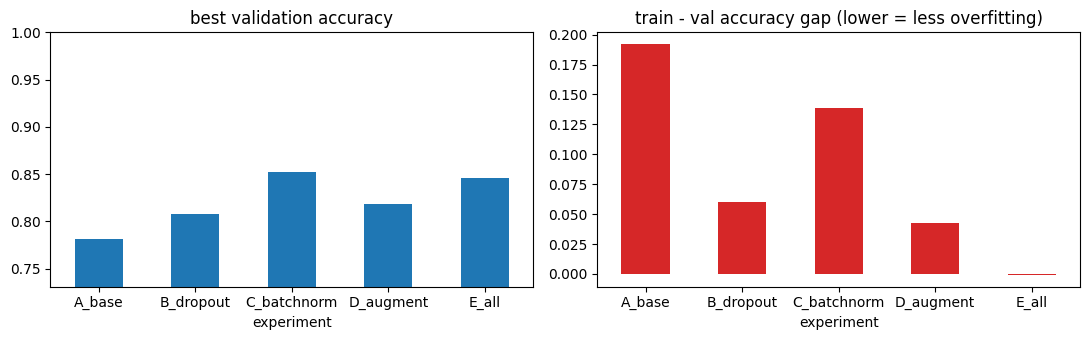

In [15]:
t1 = summary_table(exp1); display(t1); t1.to_csv(f'{RESULTS_DIR}/exp1_regularization.csv')
plot_curves(exp1, '04_exp1_curves.png', 'Experiment 1: overfitting & regularization (dashed=train, solid=val, dotted=min val loss)')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
t1['best_val_acc'].plot.bar(ax=ax[0], color='tab:blue', title='best validation accuracy'); ax[0].set_ylim(t1.best_val_acc.min() - .05, 1)
t1['gap_train_val'].plot.bar(ax=ax[1], color='tab:red', title='train - val accuracy gap (lower = less overfitting)')
for a in ax: a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/05_exp1_bars.png', dpi=130); plt.show()

**결과 해석 (실행 후 작성)** — `A_base` 의 검증 손실이 점선 이후 다시 오르면 과적합. `gap_train_val`, `val_loss_rise` 로 각 처방의 효과를 수치로 비교.

## 7. 실험 2 — 하이퍼파라미터 비교
`E_all` 설정을 기준으로, **한 그룹에서 한 가지만** 바꿔 비교합니다 (기준 설정은 저장된 결과 재사용).

비교 그룹: 학습률 · 배치 크기 · 옵티마이저 · Dropout p · 증강 강도 · 스케줄러 · 클래스 가중치 · **모델 크기(필터 수)**

In [16]:
HP_GRID = {
    'lr':           {'lr=1e-2': dict(lr=1e-2), 'lr=1e-3': dict(lr=1e-3), 'lr=1e-4': dict(lr=1e-4)},
    'batch_size':   {'bs=32': dict(batch_size=32), 'bs=64': dict(batch_size=64), 'bs=128': dict(batch_size=128)},
    'optimizer':    {'SGD': dict(optimizer='SGD', lr=1e-2), 'Adam': dict(optimizer='Adam'),
                     'AdamW': dict(optimizer='AdamW', weight_decay=1e-2)},
    'dropout':      {'p=0.3': dict(dropout=0.3), 'p=0.5': dict(dropout=0.5), 'p=0.7': dict(dropout=0.7)},
    'augmentation': {'none': dict(aug='none'), 'light': dict(aug='light'), 'strong': dict(aug='strong')},
    'scheduler':    {'none': dict(scheduler='none'), 'cosine': dict(scheduler='cosine'), 'plateau': dict(scheduler='plateau')},
    'class_weight': {'no weight': dict(class_weight=False), 'inv-freq weight': dict(class_weight=True)},
    'model_width':  {'base (32→256)': dict(channels=[32, 64, 128, 256]), 'wide (64→512)': dict(channels=[64, 128, 256, 512])},
}
hp_results = {}
for group, options in HP_GRID.items():
    print(f'\n========== 그룹: {group} ==========')
    hp_results[group] = [run_cached(name, ov, EPOCHS_HP) for name, ov in options.items()]


========== 그룹: lr ==========
✔ [lr=1e-2] 저장된 결과 사용 (best val acc 0.7164)
✔ [lr=1e-3] 저장된 결과 사용 (best val acc 0.7943)
✔ [lr=1e-4] 저장된 결과 사용 (best val acc 0.8081)

========== 그룹: batch_size ==========
✔ [bs=32] 저장된 결과 사용 (best val acc 0.7943)
✔ [bs=64] 저장된 결과 사용 (best val acc 0.7943)
✔ [bs=128] 저장된 결과 사용 (best val acc 0.7948)

========== 그룹: optimizer ==========
✔ [SGD] 저장된 결과 사용 (best val acc 0.7986)
✔ [Adam] 저장된 결과 사용 (best val acc 0.7943)
✔ [AdamW] 저장된 결과 사용 (best val acc 0.7840)

========== 그룹: dropout ==========
✔ [p=0.3] 저장된 결과 사용 (best val acc 0.7982)
✔ [p=0.5] 저장된 결과 사용 (best val acc 0.7943)
✔ [p=0.7] 저장된 결과 사용 (best val acc 0.7444)

========== 그룹: augmentation ==========
✔ [none] 저장된 결과 사용 (best val acc 0.8072)
✔ [light] 저장된 결과 사용 (best val acc 0.7943)
✔ [strong] 저장된 결과 사용 (best val acc 0.7560)

========== 그룹: scheduler ==========
✔ [none] 저장된 결과 사용 (best val acc 0.7943)
✔ [cosine] 저장된 결과 사용 (best val acc 0.8038)
✔ [plateau] 저장된 결과 사용 (best val acc 0.7943)

========== 그룹: class

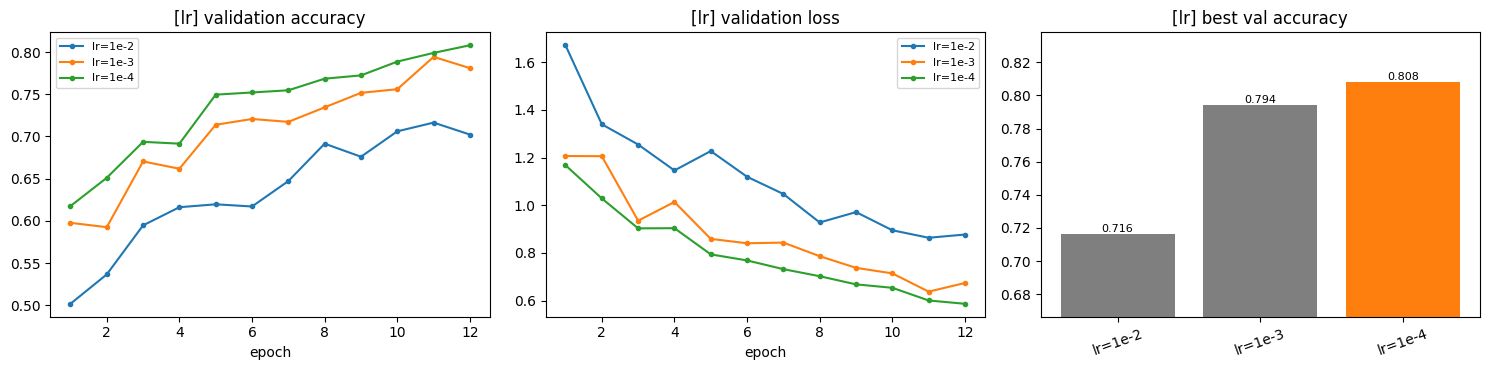

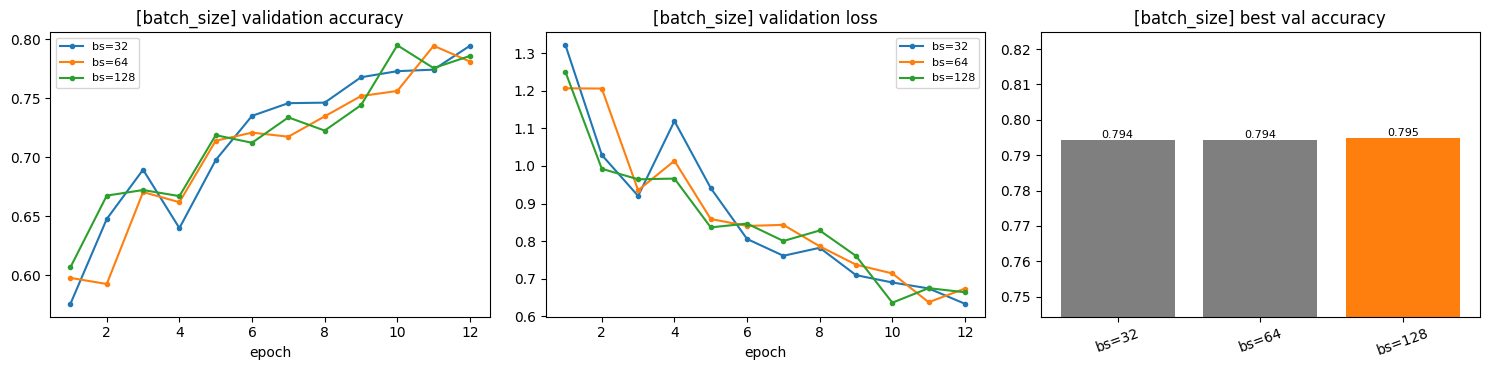

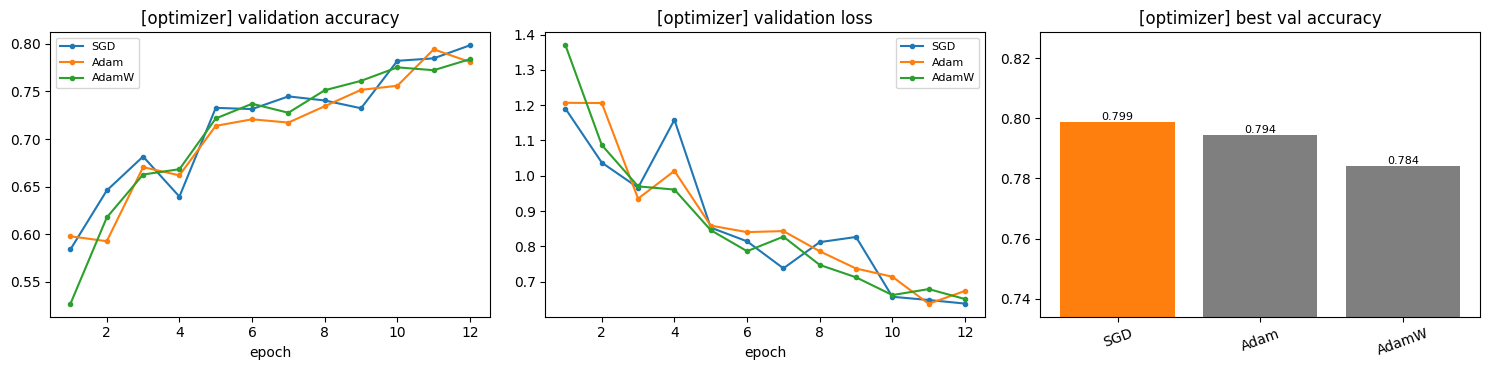

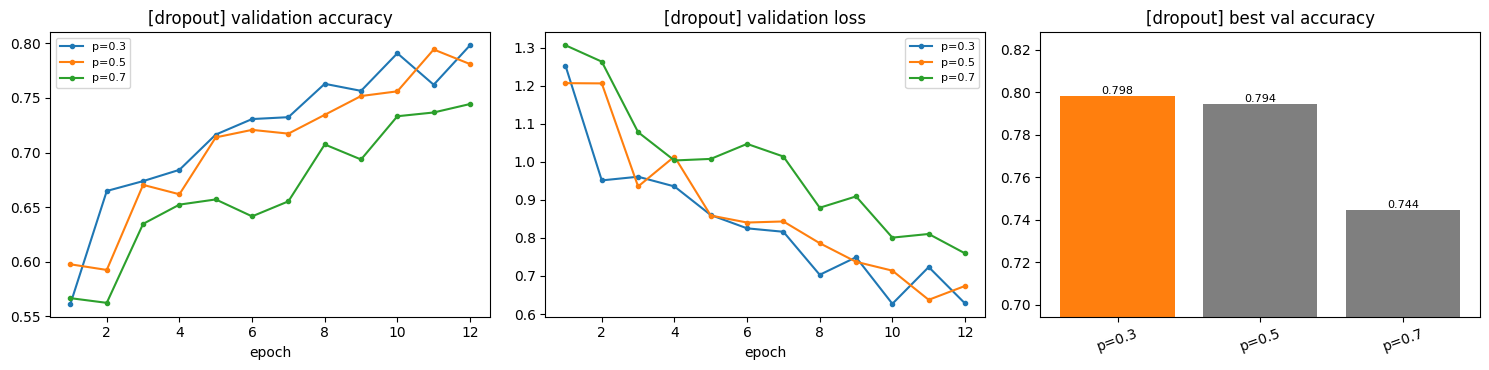

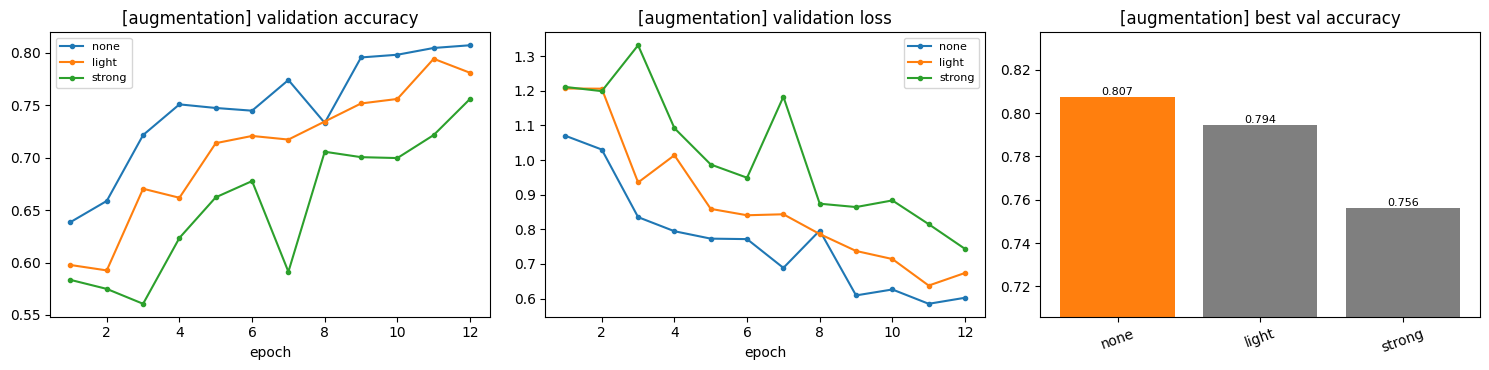

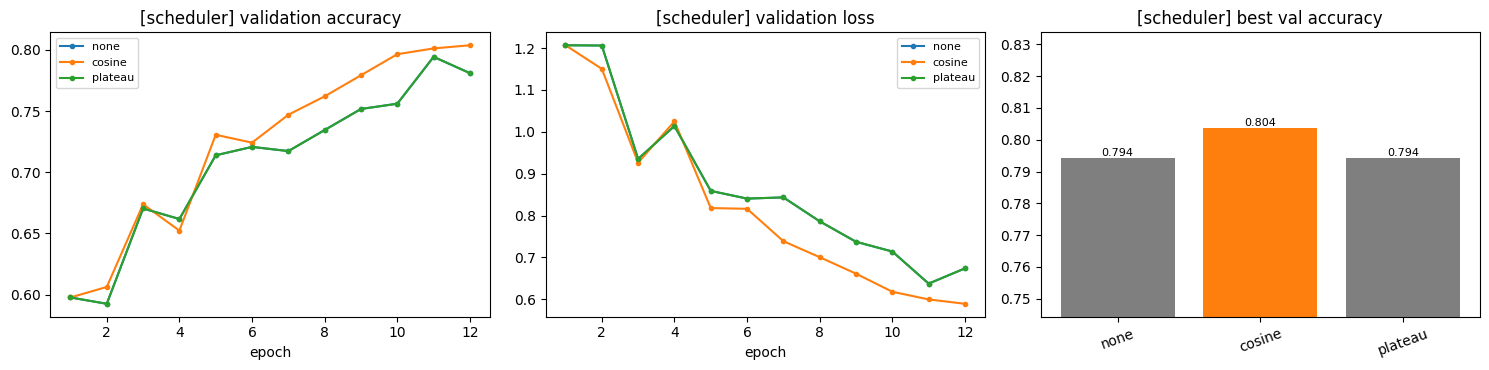

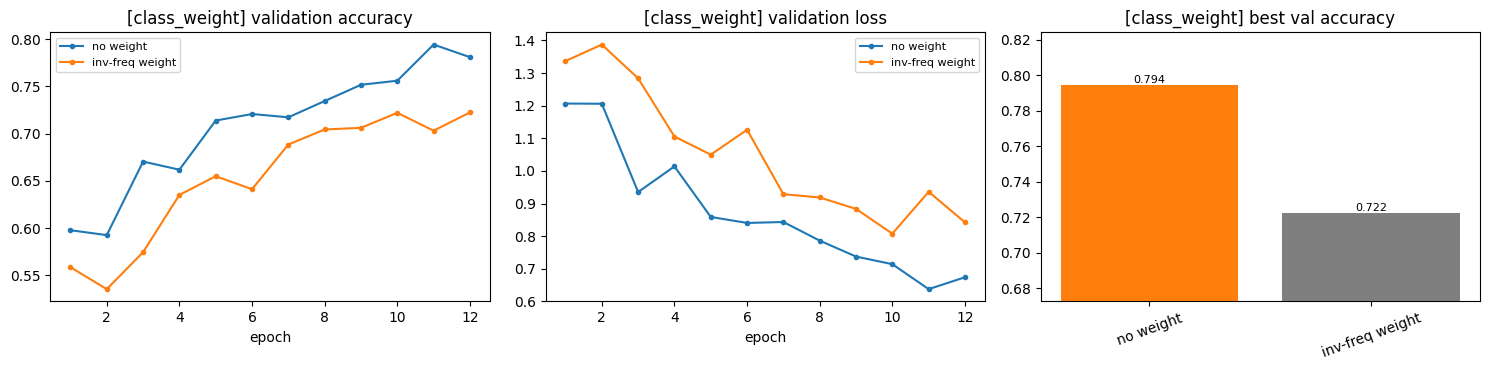

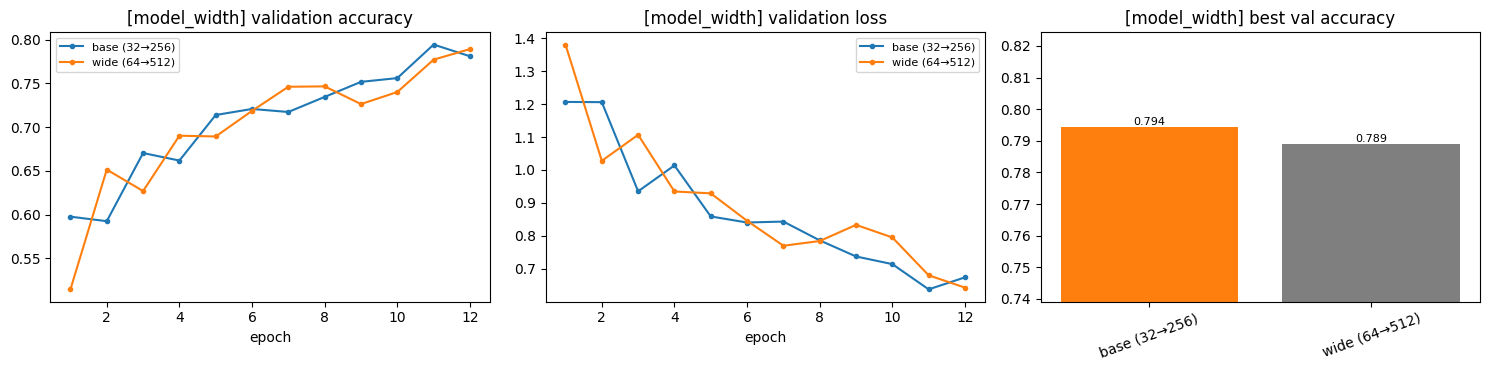

best_val_acc  best_epoch  final_train_acc  \
group        setting                                                      
lr           lr=1e-2                0.7164          11           0.6969   
             lr=1e-3                0.7943          11           0.7639   
             lr=1e-4                0.8081          12           0.7867   
batch_size   bs=32                  0.7943          12           0.7502   
             bs=64                  0.7943          11           0.7639   
             bs=128                 0.7948          10           0.7879   
optimizer    SGD                    0.7986          12           0.7744   
             Adam                   0.7943          11           0.7639   
             AdamW                  0.7840          12           0.7703   
dropout      p=0.3                  0.7982          12           0.7960   
             p=0.5                  0.7943          11           0.7639   
             p=0.7                  0.7444          12           0.7153   
augmentation none                   0.8072          12           0.8310   
             light                  0.7943          11           0.7639   
             strong                 0.7560          12           0.7053   
scheduler    none                   0.7943          11           0.7639   
             cosine                 0.8038          12           0.7914   
             plateau                0.7943          11           0.7639   
class_weight no weight              0.7943          11           0.7639   
             inv-freq weight        0.7225          12           0.7106   
model_width  base (32→256)          0.7943          11           0.7639   
             wide (64→512)          0.7892          12           0.7690   

                              final_val_acc  gap_train_val  min_val_loss  \
group        setting                                                       
lr           lr=1e-2                 0.7022        -0.0053        0.8635   
             lr=1e-3                 0.7810        -0.0171        0.6374   
             lr=1e-4                 0.8081        -0.0214        0.5864   
batch_size   bs=32                   0.7943        -0.0441        0.6333   
             bs=64                   0.7810        -0.0171        0.6374   
             bs=128                  0.7857         0.0022        0.6362   
optimizer    SGD                     0.7986        -0.0242        0.6380   
             Adam                    0.7810        -0.0171        0.6374   
             AdamW                   0.7840        -0.0137        0.6509   
dropout      p=0.3                   0.7982        -0.0022        0.6270   
             p=0.5                   0.7810        -0.0171        0.6374   
             p=0.7                   0.7444        -0.0291        0.7594   
augmentation none                    0.8072         0.0238        0.5847   
             light                   0.7810        -0.0171        0.6374   
             strong                  0.7560        -0.0508        0.7433   
scheduler    none                    0.7810        -0.0171        0.6374   
             cosine                  0.8038        -0.0124        0.5892   
             plateau                 0.7810        -0.0171        0.6374   
class_weight no weight               0.7810        -0.0171        0.6374   
             inv-freq weight         0.7225        -0.0118        0.8076   
model_width  base (32→256)           0.7810        -0.0171        0.6374   
             wide (64→512)           0.7892        -0.0201        0.6427   

                              time_sec  
group        setting                    
lr           lr=1e-2          270.7542  
             lr=1e-3          270.4171  
             lr=1e-4          268.5995  
batch_size   bs=32            264.6735  
             bs=64            270.4171  
             bs=128           268.5812  
optimizer    SGD              269.0524  
             Adam             270.4

,best setting,best_val_acc
group,,
lr,lr=1e-4,0.8081
batch_size,bs=128,0.7948
optimizer,SGD,0.7986
dropout,p=0.3,0.7982
augmentation,none,0.8072
scheduler,cosine,0.8038
class_weight,no weight,0.7943
model_width,base (32→256),0.7943


최종 CNN 설정: {'model': 'cnn', 'img_size': 160, 'channels': [32, 64, 128, 256], 'use_bn': True, 'dropout': 0.3, 'aug': 'none', 'optimizer': 'SGD', 'lr': 0.01, 'weight_decay': 0.0, 'batch_size': 128, 'scheduler': 'cosine', 'class_weight': False}


In [17]:
rows = []
for gi, (group, res) in enumerate(hp_results.items()):
    plot_group(res, group, f'06_hp_{gi}_{group}.png')
    rows += [{'group': group, 'setting': r['name'], **{k: r['summary'][k] for k in
              ['best_val_acc', 'best_epoch', 'final_train_acc', 'final_val_acc', 'gap_train_val', 'min_val_loss', 'time_sec']}} for r in res]
hp_table = pd.DataFrame(rows).set_index(['group', 'setting']).round(4)
display(hp_table); hp_table.to_csv(f'{RESULTS_DIR}/exp2_hyperparameters.csv')

best_overrides, best_rows = {}, []
for group, res in hp_results.items():
    win = max(res, key=lambda r: r['summary']['best_val_acc'])
    best_overrides.update(HP_GRID[group][win['name']])
    best_rows.append({'group': group, 'best setting': win['name'], 'best_val_acc': round(win['summary']['best_val_acc'], 4)})
display(pd.DataFrame(best_rows).set_index('group'))
FINAL_CFG = {**BASE_CFG, **best_overrides}
print('최종 CNN 설정:', FINAL_CFG)

## 8. 최종 CNN — 선택한 하이퍼파라미터 + 조기 종료, SEED 3개
실험 2 에서 고른 설정으로 더 길게 학습하되, 검증 손실이 8 에폭 동안 좋아지지 않으면 멈춥니다(조기 종료).
같은 설정을 **SEED 만 바꿔 3번** 학습합니다. 초기 가중치·데이터 순서가 달라 서로 조금씩 다른 실수를 하므로,
9장에서 예측을 평균 내면(앙상블) 처음 보는 사진에 대해 더 안정적인 답을 냅니다.

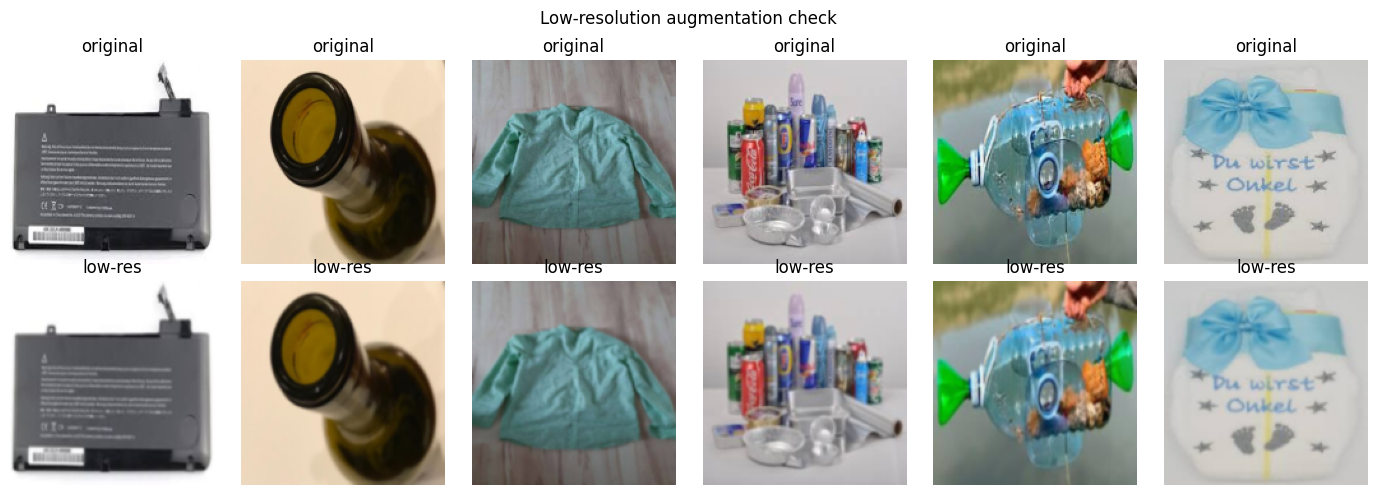


========== final_cnn_s42 ==========
✔ 저장된 모델 사용: final_cnn_s42

========== final_cnn_s7 ==========
✔ 저장된 모델 사용: final_cnn_s7

========== final_cnn_s2026 ==========
✔ 저장된 모델 사용: final_cnn_s2026

========== final_aug_s42 ==========
✔ 저장된 모델 사용: final_aug_s42

========== final_aug_s7 ==========
✔ 저장된 모델 사용: final_aug_s7

========== final_aug_s2026 ==========
✔ 저장된 모델 사용: final_aug_s2026

========== final_lr_s42 ==========
  ep   1 | train loss 1.3527 acc 0.5490 | val loss 1.3207 acc 0.5607 |    40s
  ep   2 | train loss 1.0785 acc 0.6374 | val loss 1.0563 acc 0.6510 |    74s
  ep   3 | train loss 0.9909 acc 0.6681 | val loss 0.9736 acc 0.6769 |   106s
  ep   4 | train loss 0.9099 acc 0.6972 | val loss 1.0294 acc 0.6872 |   140s
  ep   5 | train loss 0.8674 acc 0.7119 | val loss 0.9348 acc 0.6824 |   174s
  ep   6 | train loss 0.8327 acc 0.7256 | val loss 0.7693 acc 0.7646 |   208s
  ep   7 | train loss 0.7723 acc 0.7394 | val loss 0.7400 acc 0.7500 |   242s
  ep   8 | train loss 0.7387 a

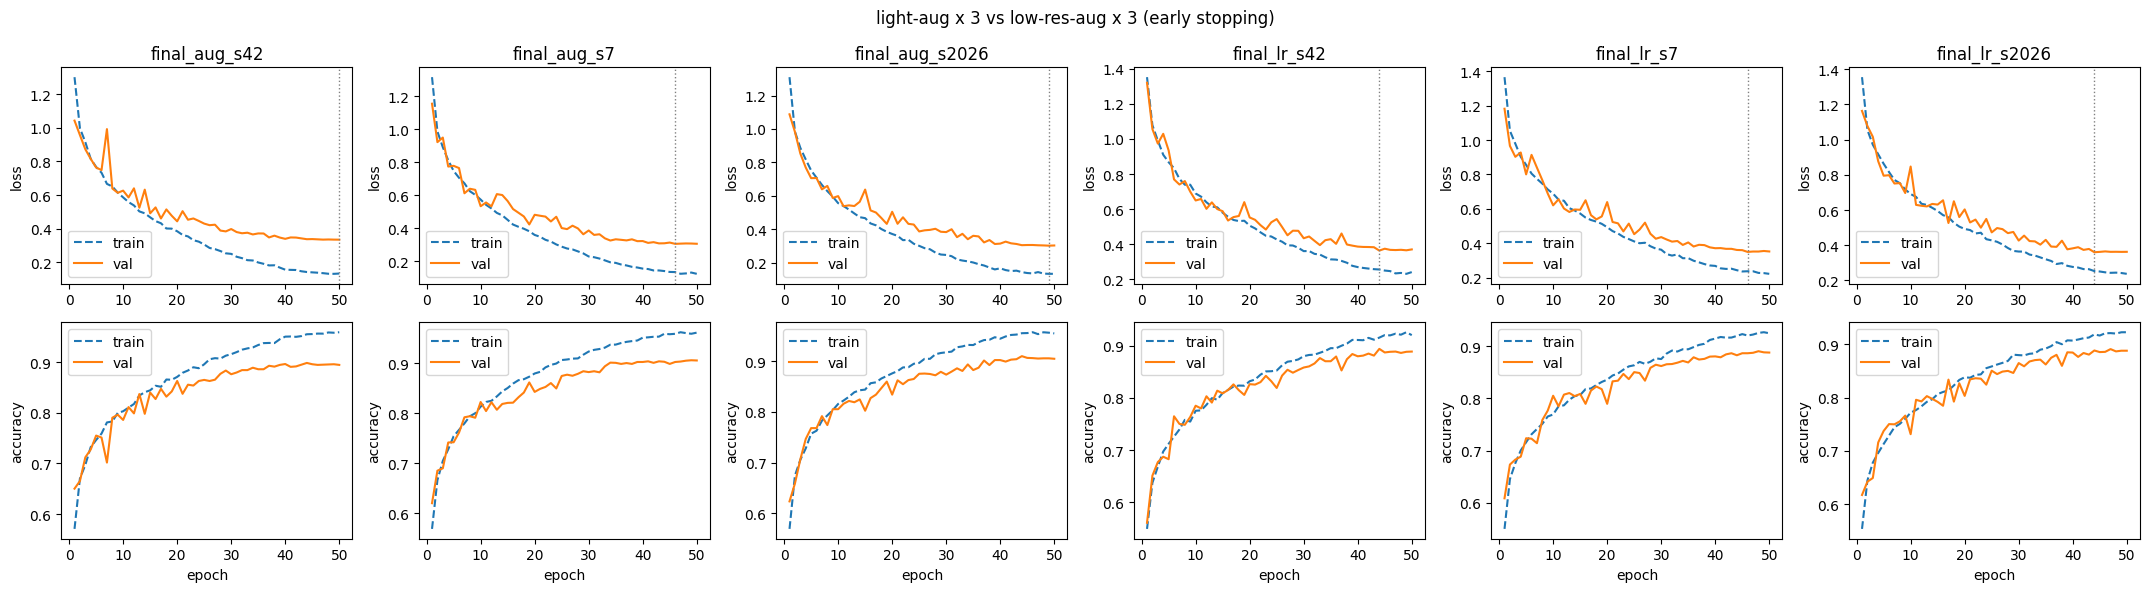

In [18]:
import glob
import torchvision.transforms.v2.functional as TF
from torchvision.transforms import InterpolationMode

# ---------------- 저해상도 증강 ----------------
# 교수님 샘플 공지: 콜라주에서 잘라낸 약 (가로 118~183) x (세로 127) 조각을 224x224 로 확대
# 우리 모델은 그걸 다시 160x160 으로 줄이므로, 학습 사진을 똑같은 과정으로 변형한다.
LR_W_RANGE = (110, 180)   # 줄일 가로 크기 (160px 기준)
LR_H_RANGE = (110, 140)   # 줄일 세로 크기 (160px 기준)
LR_MID     = 224          # 교수님이 확대한 크기
LR_PROB    = 0.5          # 학습 사진 중 저해상도 변형을 적용할 비율

class RandomLowRes(torch.nn.Module):
    # uint8 이미지 텐서 [3, H, W] → 작게 줄였다가 224 로 확대 → 다시 원래 크기로 축소
    def __init__(self, p=LR_PROB):
        super().__init__()
        self.p = p
    def forward(self, img):
        if torch.rand(1).item() >= self.p:
            return img
        out = img.shape[-1]; s = out / 160
        w = int(round(float(torch.empty(1).uniform_(*LR_W_RANGE)) * s))
        h = int(round(float(torch.empty(1).uniform_(*LR_H_RANGE)) * s))
        mode = InterpolationMode.BICUBIC if torch.rand(1).item() < 0.5 else InterpolationMode.BILINEAR
        x = TF.resize(img, [h, w], antialias=True)                                   # 작은 조각
        x = TF.resize(x, [int(LR_MID * s)] * 2, interpolation=mode, antialias=True)   # 224x224 확대 (비율 찌그러짐 포함)
        return TF.resize(x, [out, out], antialias=True)                              # 모델 입력 크기로

def degrade_fixed(X, seed):
    # 검증·시험 세트용: 사진마다 정해진(재현 가능한) 크기로 저해상도 변형을 항상 적용
    rng = np.random.RandomState(seed)
    out = X[-1].shape[-1] if len(X) else IMG_SIZE; s = out / 160
    res = torch.empty_like(X)
    for i in range(len(X)):
        w = int(round(rng.uniform(*LR_W_RANGE) * s)); h = int(round(rng.uniform(*LR_H_RANGE) * s))
        x = TF.resize(X[i], [h, w], antialias=True)
        x = TF.resize(x, [int(LR_MID * s)] * 2, antialias=True)
        res[i] = TF.resize(x, [out, out], antialias=True)
    return res

# make_transform 에 'lowres' 추가 (none / light / strong 은 기존과 완전히 같음)
def make_transform(aug='none', mean=None, std=None, size=IMG_SIZE):
    ops = []
    if aug in ('light', 'strong'):
        ops += [v2.RandomHorizontalFlip(), v2.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1))]
    if aug == 'strong':
        ops = [v2.RandomResizedCrop(size, scale=(0.7, 1.0), antialias=True), v2.RandomVerticalFlip(p=0.2),
               v2.ColorJitter(brightness=0.2, contrast=0.2)] + ops
    if aug == 'lowres':   # 과감한 자르기(물건이 잘린 구도) + light 증강 + 저해상도 변형
        ops = [v2.RandomResizedCrop(size, scale=(0.6, 1.0), antialias=True), v2.RandomHorizontalFlip(),
               v2.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1)), RandomLowRes()]
    ops += [v2.ToDtype(torch.float32, scale=True)]
    if mean is not None:
        ops += [v2.Normalize(mean, std)]
    return v2.Compose(ops)

# ---------------- 흐린 정도 눈으로 확인 ----------------
# 교수님 샘플 60장 폴더가 있으면 경로를 넣으세요 (비교 그림에만 쓰고, 학습·선택에는 전혀 쓰지 않음)
SAMPLE_DIR = ''   # 예: '/content/drive/MyDrive/garbage_classification_synthetic_test_60'

idx = [int(np.where(y_val.numpy() == c)[0][0]) for c in range(0, 12, 2)]
demo = degrade_fixed(X_val[idx], seed=0)
samples = sorted(p for p in glob.glob(f'{SAMPLE_DIR}/**/*', recursive=True)
                 if 'collage' in p.lower() and p.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')))[:6] if SAMPLE_DIR else []
rows = 3 if samples else 2
fig, axes = plt.subplots(rows, 6, figsize=(14, 2.5 * rows))
for j, i in enumerate(idx):
    axes[0, j].imshow(X_val[i].permute(1, 2, 0)); axes[0, j].set_title('original'); axes[0, j].axis('off')
    axes[1, j].imshow(demo[j].permute(1, 2, 0)); axes[1, j].set_title('low-res'); axes[1, j].axis('off')
for j, p in enumerate(samples):
    axes[2, j].imshow(Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    axes[2, j].set_title('sample (collage)'); axes[2, j].axis('off')
if samples:
    for j in range(len(samples), 6): axes[2, j].axis('off')
plt.suptitle('Low-resolution augmentation check'); plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/12_lowres_check.png', dpi=120); plt.show()

# ---------------- 최종 모델 학습 (기존 6개는 불러오기) ----------------
FINAL_CFG_AUG = {**FINAL_CFG, 'aug': 'light',  'dropout': 0.3}
FINAL_CFG_LR  = {**FINAL_CFG, 'aug': 'lowres', 'dropout': 0.3}

finals = {}
for tag, cfg_use in [('final_cnn', FINAL_CFG), ('final_aug', FINAL_CFG_AUG), ('final_lr', FINAL_CFG_LR)]:
    for seed in FINAL_SEEDS:
        name = f'{tag}_s{seed}'
        print(f'\n========== {name} ==========')
        if os.path.exists(f'{MODEL_DIR}/{name}.pt') and not RETRAIN:
            model, cfg, hist = load_final(name)
        else:
            model, summ, hist = train_model(cfg_use, EPOCHS_FINAL, early_stop=PATIENCE, seed=seed)
            save_final(model, cfg_use, name, hist)
            cfg = cfg_use
        finals[name] = (model, cfg, hist)

plot_curves([{'name': n, 'hist': h} for n, (_, _, h) in finals.items() if h and n.startswith(('final_aug', 'final_lr'))],
            '07b_final_aug_vs_lowres_curves.png', 'light-aug x 3 vs low-res-aug x 3 (early stopping)')


## 9. 최종 모델 선택 — 검증 정확도가 가장 높은 조합
아래 후보를 모두 **검증(val) 데이터**로 비교해 정확도가 가장 높은 것을 고릅니다.
- 단일 모델 3개 / 2개 평균 / 3개 평균 (앙상블)
- 각각 좌우반전 평균(TTA) 사용 여부 — 4장의 좌우 반전 증강을 예측 때도 적용하는 것

고른 조합은 `models/best_setup.json` 에 저장되고, **맨 위 평가 셀이 이 파일을 읽어 그대로 사용**합니다.
시험(test) 정확도는 고르는 데 쓰지 않고 최종 성능 보고에만 씁니다.

In [19]:
W_CLEAR, W_LOWRES = 0.5, 0.5     # 선택 기준 가중치 (선명 : 흐림)

@torch.no_grad()
def predict_X(model, X, tta=False):
    loader = DataLoader(TensorImageDataset(X, torch.zeros(len(X), dtype=torch.long), make_transform('none', DATA_MEAN, DATA_STD)),
                        256, num_workers=NUM_WORKERS)
    model.eval(); probs = []
    for x, _ in loader:
        x = x.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            p = torch.softmax(model(x).float(), 1)
            if tta:
                p = (p + torch.softmax(model(torch.flip(x, dims=[3])).float(), 1)) / 2
        probs.append(p.float().cpu())
    return torch.cat(probs).numpy()

def predict(model, cfg, split='test', tta=False):   # 아래 셀들과의 호환용
    return predict_X(model, SPLITS[split], tta)

# 흐린 검증·시험 세트 (사진마다 정해진 크기로 저해상도 변형, 매번 같은 결과)
X_val_lr, X_test_lr = degrade_fixed(X_val, seed=1), degrade_fixed(X_test, seed=2)
SPLITS = {'val': X_val, 'val_lr': X_val_lr, 'test': X_test, 'test_lr': X_test_lr}
Y = {'val': y_val.numpy(), 'val_lr': y_val.numpy(), 'test': y_test.numpy(), 'test_lr': y_test.numpy()}

# 이전 선택 기록 (비교용)
PREV = None
if os.path.exists(f'{MODEL_DIR}/best_setup.json'):
    with open(f'{MODEL_DIR}/best_setup.json', encoding='utf-8') as f:
        PREV = json.load(f)

names = list(finals)
P = {(n, s, t): predict_X(m, SPLITS[s], t) for n, (m, c, _) in finals.items() for s in SPLITS for t in (False, True)}

# 단일 모델 성능
single = pd.DataFrame([{'model': n, **{f'{s}_acc': (P[(n, s, False)].argmax(1) == Y[s]).mean() for s in SPLITS}} for n in names])
display(single.set_index('model').round(4))

# 모든 조합 평가 (모델 9개 → 511개 조합 × TTA 2 = 1,022개 후보)
rows = []
for k in range(1, len(names) + 1):
    for combo in itertools.combinations(names, k):
        for t in (False, True):
            r = dict(models=' + '.join(combo), n_models=k, tta=t)
            for s in SPLITS:
                r[f'{s}_acc'] = (np.mean([P[(n, s, t)] for n in combo], 0).argmax(1) == Y[s]).mean()
            r['score'] = W_CLEAR * r['val_acc'] + W_LOWRES * r['val_lr_acc']
            rows.append(r)
sel = pd.DataFrame(rows).sort_values(['score', 'n_models', 'tta'], ascending=[False, True, True]).reset_index(drop=True)
sel = sel[['models', 'n_models', 'tta', 'score', 'val_acc', 'val_lr_acc', 'test_acc', 'test_lr_acc']]
display(sel.head(15).round(4))
sel.to_csv(f'{RESULTS_DIR}/model_selection.csv', index=False)

best = sel.iloc[0]
BEST_MODELS = best['models'].split(' + ')
SETUP = dict(models=[f'{n}.pt' for n in BEST_MODELS], tta=bool(best['tta']),
             val_acc=float(best['val_acc']), val_lr_acc=float(best['val_lr_acc']), score=float(best['score']),
             test_acc=float(best['test_acc']), test_lr_acc=float(best['test_lr_acc']),
             selection=f'{W_CLEAR} x 선명 검증 + {W_LOWRES} x 흐린 검증')

# 이전 선택과 비교
cmp_rows = [dict(구분='새 선택', **best[['models', 'tta', 'val_acc', 'val_lr_acc', 'test_acc', 'test_lr_acc']].to_dict())]
if PREV:
    pm = ' + '.join(m[:-3] for m in PREV['models'])
    prev_row = sel[(sel.models == pm) & (sel.tta == PREV['tta'])]
    if len(prev_row):
        cmp_rows.append(dict(구분='이전 선택', **prev_row.iloc[0][['models', 'tta', 'val_acc', 'val_lr_acc', 'test_acc', 'test_lr_acc']].to_dict()))
display(pd.DataFrame(cmp_rows).set_index('구분').round(4))

with open(f'{MODEL_DIR}/best_setup.json', 'w', encoding='utf-8') as f:
    json.dump(SETUP, f, ensure_ascii=False, indent=1)
print(f"\n🏆 최종 선택: {best['models']} | TTA {best['tta']}")
print(f"   선명 검증 {best['val_acc']:.4f} | 흐린 검증 {best['val_lr_acc']:.4f} | 선명 시험 {best['test_acc']:.4f} | 흐린 시험 {best['test_lr_acc']:.4f}")
print('   → models/best_setup.json 저장 완료')

,val_acc,val_lr_acc,test_acc,test_lr_acc
model,,,,
final_cnn_s42,0.9002,0.8481,0.8860,0.8429
final_cnn_s7,0.8929,0.8485,0.8735,0.8429
final_cnn_s2026,0.8946,0.8292,0.8769,0.8283
final_aug_s42,0.8989,0.8382,0.8834,0.8348
final_aug_s7,0.9062,0.8477,0.8946,0.8395
final_aug_s2026,0.9105,0.8451,0.8916,0.8361
final_lr_s42,0.8941,0.8980,0.8623,0.8632
final_lr_s7,0.8903,0.8976,0.8662,0.8778
final_lr_s2026,0.8911,0.8911,0.8701,0.8739


,models,n_models,tta,score,val_acc,val_lr_acc,test_acc,test_lr_acc
0,final_cnn_s42 + final_aug_s7 + final_lr_s42 + ...,4,False,0.9103,0.9187,0.9019,0.8950,0.8830
1,final_cnn_s42 + final_aug_s2026 + final_lr_s42...,4,False,0.9094,0.9157,0.9032,0.8989,0.8825
2,final_cnn_s2026 + final_lr_s42 + final_lr_s7 +...,4,False,0.9083,0.9096,0.9071,0.8881,0.8864
3,final_cnn_s42 + final_aug_s7 + final_aug_s2026...,6,False,0.9083,0.9152,0.9015,0.8959,0.8804
4,final_cnn_s42 + final_aug_s7 + final_lr_s42 + ...,5,False,0.9081,0.9131,0.9032,0.8924,0.8881
5,final_cnn_s42 + final_aug_s2026 + final_lr_s42...,5,True,0.9081,0.9127,0.9036,0.8950,0.8911
6,final_cnn_s42 + final_cnn_s7 + final_aug_s2026...,6,False,0.9081,0.9174,0.8989,0.8997,0.8855
7,final_cnn_s42 + final_cnn_s2026 + final_aug_s7...,6,False,0.9081,0.9174,0.8989,0.8937,0.8817
8,final_cnn_s42 + final_cnn_s7 + final_lr_s42 + ...,5,False,0.9079,0.9152,0.9006,0.8967,0.8894
9,final_cnn_s42 + final_cnn_s2026 + final_lr_s42...,5,False,0.9079,0.9131,0.9028,0.8950,0.8881


,models,tta,val_acc,val_lr_acc,test_acc,test_lr_acc
구분,,,,,,
새 선택,final_cnn_s42 + final_aug_s7 + final_lr_s42 + ...,False,0.9187,0.9019,0.8950,0.8830
이전 선택,final_cnn_s42 + final_cnn_s2026 + final_aug_s4...,False,0.9204,0.8606,0.9036,0.8541



🏆 최종 선택: final_cnn_s42 + final_aug_s7 + final_lr_s42 + final_lr_s7 | TTA False
   선명 검증 0.9187 | 흐린 검증 0.9019 | 선명 시험 0.8950 | 흐린 시험 0.8830
   → models/best_setup.json 저장 완료


[single_cnn] TEST accuracy = 0.8860 | macro-F1 = 0.8560

              precision    recall  f1-score   support

     battery     0.8768    0.8521    0.8643       142
  biological     0.8446    0.8446    0.8446       148
 brown-glass     0.8901    0.8901    0.8901        91
   cardboard     0.8841    0.9104    0.8971       134
     clothes     0.9456    0.9787    0.9619       799
 green-glass     0.9167    0.9565    0.9362        92
       metal     0.7373    0.7565    0.7468       115
       paper     0.8994    0.9108    0.9051       157
     plastic     0.7840    0.7597    0.7717       129
       shoes     0.8438    0.8182    0.8308       297
       trash     0.8571    0.7500    0.8000       104
 white-glass     0.8667    0.7845    0.8235       116

    accuracy                         0.8860      2324
   macro avg     0.8622    0.8510    0.8560      2324
weighted avg     0.8848    0.8860    0.8849      2324



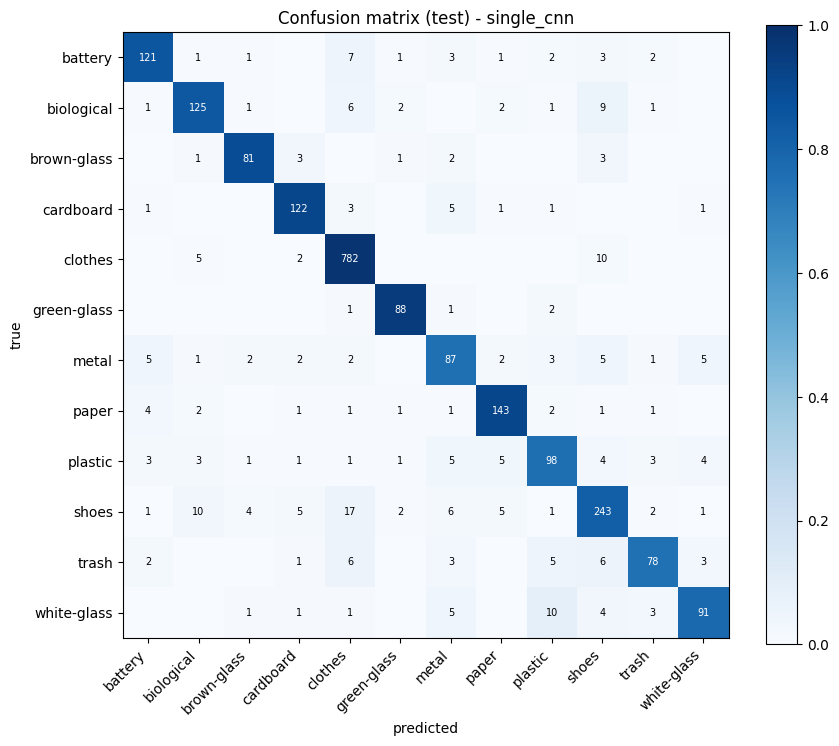

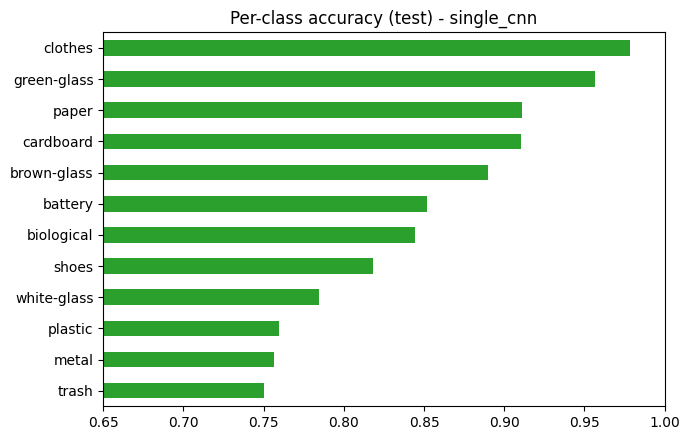

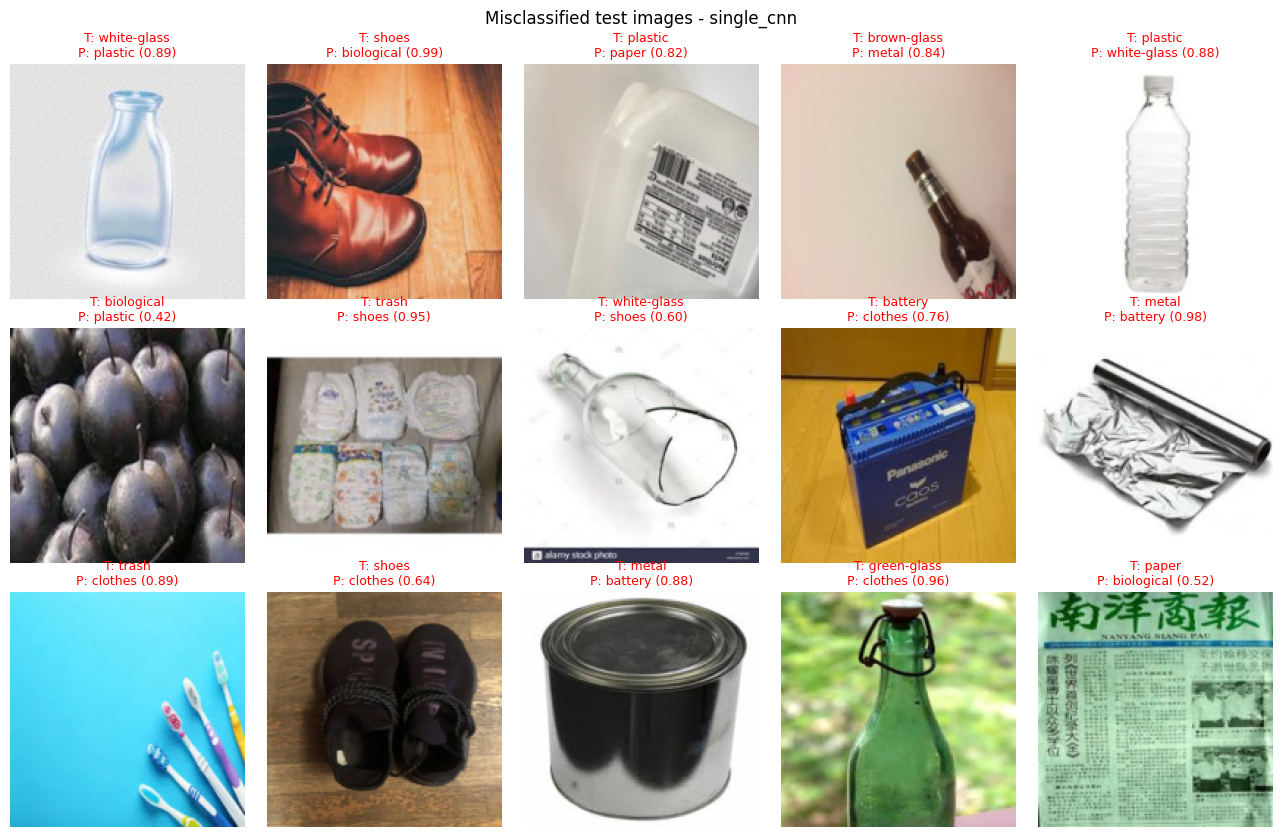

[best_setup] TEST accuracy = 0.8950 | macro-F1 = 0.8680

              precision    recall  f1-score   support

     battery     0.8117    0.8803    0.8446       142
  biological     0.8951    0.8649    0.8797       148
 brown-glass     0.9053    0.9451    0.9247        91
   cardboard     0.9070    0.8731    0.8897       134
     clothes     0.9616    0.9712    0.9664       799
 green-glass     0.9381    0.9891    0.9630        92
       metal     0.7778    0.7913    0.7845       115
       paper     0.8696    0.8917    0.8805       157
     plastic     0.7886    0.7519    0.7698       129
       shoes     0.8482    0.8653    0.8567       297
       trash     0.9070    0.7500    0.8211       104
 white-glass     0.8624    0.8103    0.8356       116

    accuracy                         0.8950      2324
   macro avg     0.8727    0.8654    0.8680      2324
weighted avg     0.8951    0.8950    0.8945      2324



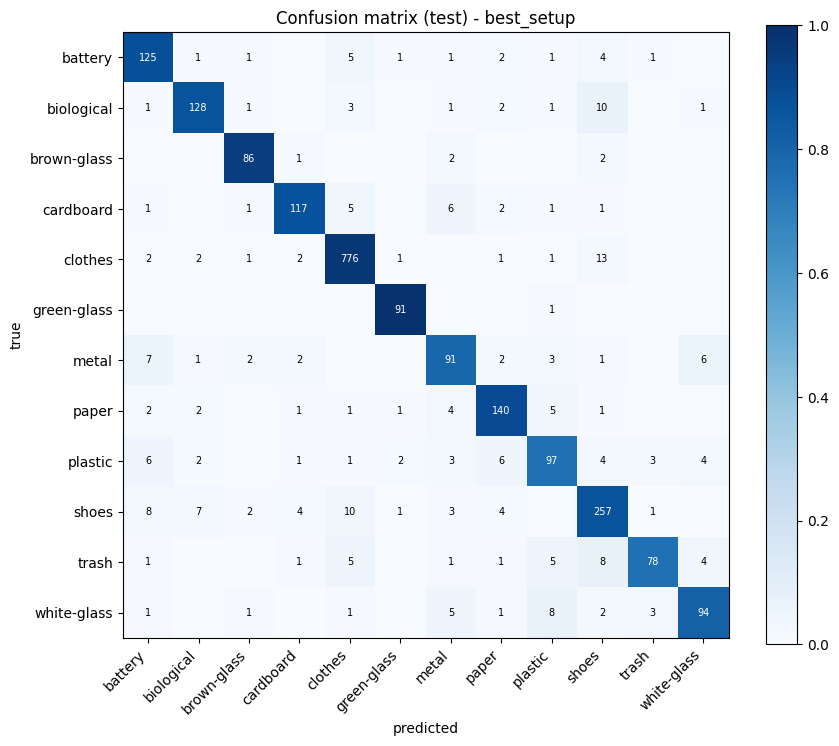

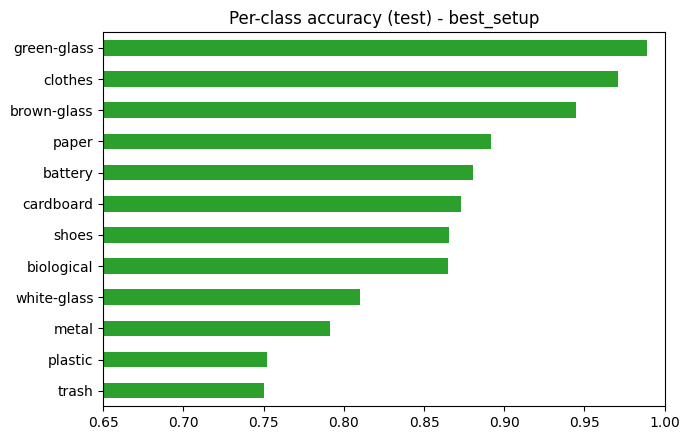

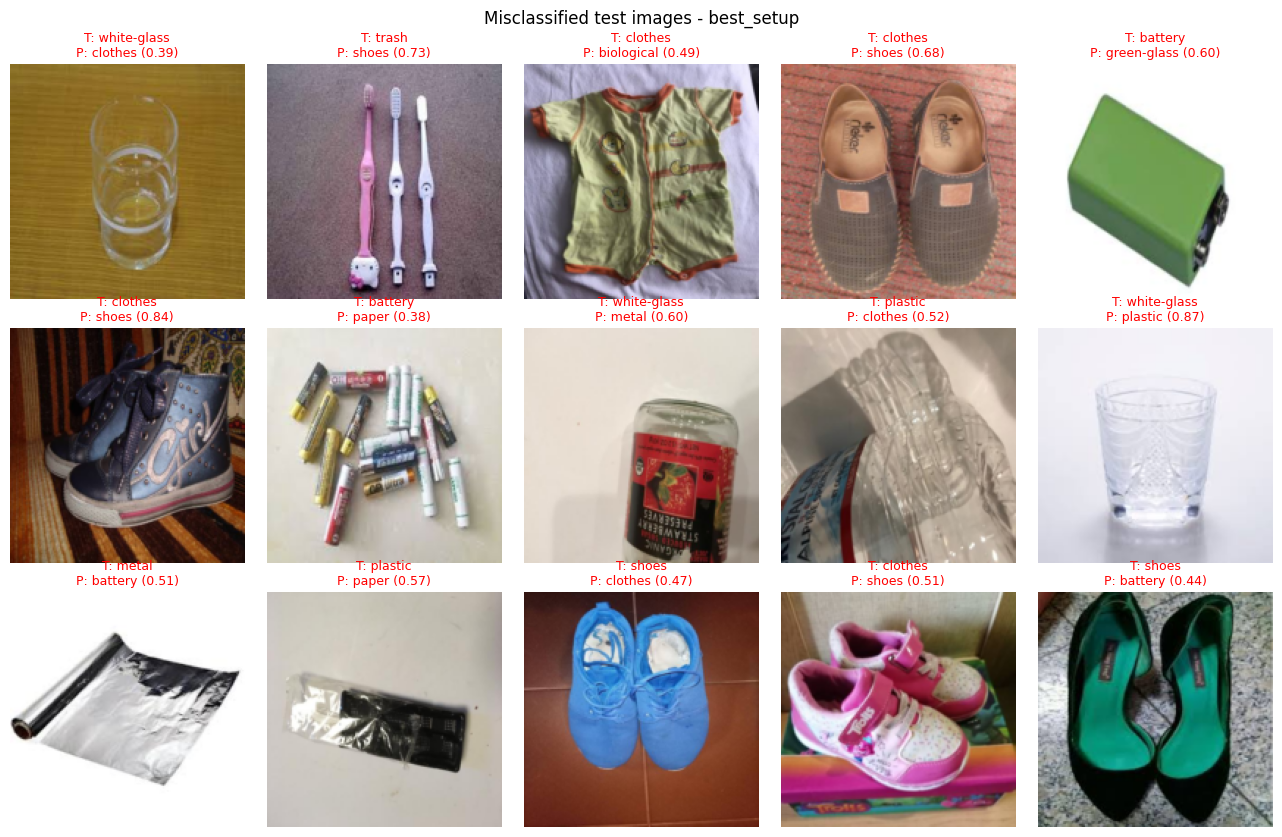

In [20]:
def evaluate_probs(prob, tag):
    pred, true = prob.argmax(1), y_test.numpy()
    acc, f1m = accuracy_score(true, pred), f1_score(true, pred, average='macro')
    print(f'[{tag}] TEST accuracy = {acc:.4f} | macro-F1 = {f1m:.4f}\n')
    print(classification_report(true, pred, target_names=CLASSES, digits=4, zero_division=0))
    pd.DataFrame(classification_report(true, pred, target_names=CLASSES, digits=4, output_dict=True, zero_division=0)).T.round(4) \
      .to_csv(f'{RESULTS_DIR}/test_report_{tag}.csv')
    cm = confusion_matrix(true, pred); cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); plt.colorbar(im)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if cmn[i, j] > .5 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'Confusion matrix (test) - {tag}')
    plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/09_cm_{tag}.png', dpi=130); plt.show()
    per_cls = pd.Series(np.diag(cmn), index=CLASSES).sort_values()
    per_cls.plot.barh(figsize=(7, 4.5), color='tab:green', title=f'Per-class accuracy (test) - {tag}')
    plt.xlim(max(0, per_cls.min() - .1), 1); plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/10_per_class_{tag}.png', dpi=130); plt.show()
    wrong = np.where(pred != true)[0]
    if len(wrong):
        pick = np.random.RandomState(SEED).choice(wrong, min(15, len(wrong)), replace=False)
        fig, axes = plt.subplots(3, 5, figsize=(13, 8.5))
        for ax, i in zip(axes.flat, pick):
            ax.imshow(X_test[i].permute(1, 2, 0)); ax.axis('off')
            ax.set_title(f'T: {CLASSES[true[i]]}\nP: {CLASSES[pred[i]]} ({prob[i].max():.2f})', fontsize=9, color='red')
        for ax in axes.flat[len(pick):]: ax.axis('off')
        plt.suptitle(f'Misclassified test images - {tag}'); plt.tight_layout()
        plt.savefig(f'{RESULTS_DIR}/figures/11_errors_{tag}.png', dpi=110); plt.show()
    return dict(model=tag, test_acc=acc, test_macro_f1=f1m)

final_results = [evaluate_probs(P[(names[0], 'test', False)], 'single_cnn')]
final_results.append(evaluate_probs(np.mean([P[(n, 'test', SETUP['tta'])] for n in BEST_MODELS], 0), 'best_setup'))

### 📤 평가용 모델을 GitHub 에 올리기 (제출 전 필수)
교수님 Colab 에서는 내 구글 드라이브에 접근할 수 없으므로, 평가에 쓰일 파일을 GitHub 에 올려야 합니다.
1. 드라이브 `hackathon_results/models/` 에서 **`best_setup.json` 과 그 안에 적힌 `.pt` 파일들**을 내려받기 (파일당 25MB 미만이라 웹으로 업로드 가능)
2. GitHub 저장소에 `models` 폴더를 만들어 업로드 (**Add file → Upload files**, 경로 앞에 `models/` 입력)
3. 맨 위 평가 셀의 `MODEL_REPO` 를 `https://github.com/<아이디>/<저장소>/blob/main/models` 로 수정
4. **새 Colab 창**에서 평가 셀 두 개만 실행해 정상 동작하는지 확인 (리허설)

In [21]:
print('GitHub models/ 폴더에 올릴 파일:')
for f in ['best_setup.json'] + SETUP['models']:
    print(f'  - {f:28s} {os.path.getsize(f"{MODEL_DIR}/{f}")/1e6:7.1f} MB')

GitHub models/ 폴더에 올릴 파일:
  - best_setup.json                  0.0 MB
  - final_cnn_s42.pt                 4.5 MB
  - final_aug_s7.pt                  4.5 MB
  - final_lr_s42.pt                  4.5 MB
  - final_lr_s7.pt                   4.5 MB


## 10. 최종 결과 요약 (보고서용)

In [23]:
final_table = pd.DataFrame(final_results).set_index('model').round(4)
display(final_table); final_table.to_csv(f'{RESULTS_DIR}/final_test_results.csv')
for name, t in [('실험 1: 규제 기법 비교', t1), ('실험 2: 하이퍼파라미터 비교', hp_table),
                ('모델 조합 선택', sel.round(4).set_index('models')), ('최종 시험 결과', final_table)]:
    print(f'\n## {name}')
    try: print(t.to_markdown())
    except ImportError: print(t.to_string())
print('\n그림 파일 위치:', f'{RESULTS_DIR}/figures')

,test_acc,test_macro_f1
model,,
single_cnn,0.886,0.856
best_setup,0.895,0.868



## 실험 1: 규제 기법 비교
| experiment   |   best_val_acc |   best_epoch |   final_train_acc |   final_val_acc |   gap_train_val |   min_val_loss |   final_val_loss |   val_loss_rise |   epochs_run |   time_sec |
|:-------------|---------------:|-------------:|------------------:|----------------:|----------------:|---------------:|-----------------:|----------------:|-------------:|-----------:|
| A_base       |         0.781  |           11 |            0.9712 |          0.7788 |          0.1923 |         0.7456 |           1.2648 |          0.5192 |           25 |    366.136 |
| B_dropout    |         0.8081 |           22 |            0.863  |          0.8029 |          0.0601 |         0.6314 |           0.6576 |          0.0262 |           25 |    368.391 |
| C_batchnorm  |         0.852  |           25 |            0.9906 |          0.852  |          0.1386 |         0.5341 |           0.5758 |          0.0417 |           25 |    427.69  |
| D_augment    |         0.8188 |           21

## 11. 결론 (실행 후 작성)
- 과적합: …
- 가장 효과가 컸던 규제 기법: …
- 하이퍼파라미터별 영향: …
- 단일 모델 vs 앙상블·TTA: …
- 최종 선택 조합과 검증 / 시험 정확도: …
- 자주 틀리는 클래스 쌍과 원인 (예: 유리 3종, paper ↔ cardboard, plastic ↔ trash): …
- 한계와 개선 방향: …

## 참고문헌 / 데이터 출처
1. Mostafa Mohamed, *Garbage Classification (12 classes)*, Kaggle — https://www.kaggle.com/datasets/mostafaabla/garbage-classification
2. (추가 데이터 사용 시) …
3. 빅데이터프로그래밍 2026 강의자료 9주차 — 과적합, Dropout, BatchNorm, 데이터 증강

## 생성형 AI 사용 기록
| 도구 | 용도 | 프롬프트 |
|---|---|---|
| Claude (Anthropic) | 노트북 구조·코드 초안 작성 | (사용한 프롬프트를 그대로 기입) |

In [22]:

#   결과: hackathon_results/submission/ 에
#         submission.py      (load_model, get_transform, CLASSES 포함)
#         model_weights.pt   (최종 앙상블 가중치 파일 1개)
#   학습 셀을 다시 돌릴 필요 없음 (드라이브의 models 폴더만 있으면 됨)
# ======================================================================
import os, sys, json, glob, random, importlib.util
import numpy as np
import torch
from PIL import Image, ImageOps

MODEL_DIR = '/content/drive/MyDrive/hackathon_results/models'      # best_setup.json 과 .pt 가 있는 곳
OUT_DIR   = '/content/drive/MyDrive/hackathon_results/submission'  # 제출 파일을 저장할 곳
DATA_DIR  = '/content/garbage_data'                                 # 자체 점검용 Kaggle 이미지 (없으면 점검 생략)

if 'google.colab' in sys.modules and not os.path.isdir('/content/drive/MyDrive'):
    from google.colab import drive; drive.mount('/content/drive')
os.makedirs(OUT_DIR, exist_ok=True)

# ---------- 1) 최종 조합과 모델 파일 읽기 ----------
with open(f'{MODEL_DIR}/best_setup.json', encoding='utf-8') as f:
    setup = json.load(f)
cks = [torch.load(f'{MODEL_DIR}/{name}', map_location='cpu', weights_only=True) for name in setup['models']]
classes, size, mean, std = cks[0]['classes'], cks[0]['img_size'], cks[0]['mean'], cks[0]['std']
for ck in cks:
    assert ck['classes'] == classes and ck['img_size'] == size and ck['mean'] == mean and ck['std'] == std, \
        '모델끼리 클래스/전처리 설정이 다릅니다.'
member_cfgs = [dict(use_bn=bool(ck['cfg']['use_bn']), dropout=float(ck['cfg']['dropout']),
                    channels=tuple(int(c) for c in ck['cfg']['channels'])) for ck in cks]
print('최종 조합:', setup['models'], '| TTA:', setup['tta'])
print('클래스:', classes)

# ---------- 2) 가중치 파일 1개로 합치기 ----------
combined = {f'members.{i}.{k}': (v.half() if v.is_floating_point() else v)
            for i, ck in enumerate(cks) for k, v in ck['state_dict'].items()}
torch.save(combined, f'{OUT_DIR}/model_weights.pt')
print(f"✔ model_weights.pt 저장 ({os.path.getsize(f'{OUT_DIR}/model_weights.pt')/1e6:.1f} MB)")

# ---------- 3) submission.py 쓰기 ----------
SUBMISSION = '''"""
쓰레기 이미지 12종 분류 — 제출용 모델 정의
- load_model(weights_path, device): 학습 때와 같은 구조(CNN {n}개 앙상블)를 만들고 가중치를 넣어 반환
- get_transform(): PIL 이미지(RGB) 1장 -> Tensor[3, {size}, {size}] (학습·검증 때와 같은 전처리)
- CLASSES: 모델 출력 인덱스 순서 (알파벳 순)
모델 출력은 앙상블 평균 확률의 로그값이라, argmax 가 최종 예측이고 softmax 를 취하면 평균 확률이 된다.
"""
import numpy as np
import torch
import torch.nn as nn
from PIL import Image, ImageOps

CLASSES = {classes}

IMG_SIZE = {size}
MEAN = {mean}   # 학습 데이터로 계산한 채널별 평균
STD = {std}     # 학습 데이터로 계산한 채널별 표준편차
MEMBER_CFGS = {member_cfgs}
USE_TTA = {tta}


class GarbageCNN(nn.Module):
    """학습 노트북 5장의 모델과 같은 구조"""
    def __init__(self, num_classes=12, use_bn=False, dropout=0.0, channels=(32, 64, 128, 256)):
        super().__init__()
        layers, in_c = [], 3
        for c in channels:
            for _ in range(2):
                layers.append(nn.Conv2d(in_c, c, 3, padding=1, bias=not use_bn))
                if use_bn:
                    layers.append(nn.BatchNorm2d(c))
                layers.append(nn.ReLU(inplace=True))
                in_c = c
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(4)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(in_c * 16, 256),
            nn.BatchNorm1d(256) if use_bn else nn.Identity(), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


class EnsembleCNN(nn.Module):
    """여러 CNN 의 클래스 확률을 평균한다 (노트북 9장에서 고른 최종 조합)"""
    def __init__(self):
        super().__init__()
        self.members = nn.ModuleList([GarbageCNN(len(CLASSES), **cfg) for cfg in MEMBER_CFGS])

    def forward(self, x):
        probs = []
        for m in self.members:
            p = torch.softmax(m(x).float(), dim=1)
            if USE_TTA:
                p = (p + torch.softmax(m(torch.flip(x, dims=[3])).float(), dim=1)) / 2
            probs.append(p)
        return torch.log(torch.stack(probs).mean(0).clamp_min(1e-12))


def load_model(weights_path, device):
    model = EnsembleCNN()
    state = torch.load(weights_path, map_location="cpu")
    model.load_state_dict({{k: (v.float() if v.is_floating_point() else v) for k, v in state.items()}})
    return model


class Preprocess:
    """회전 정보 반영 -> RGB -> {size}x{size} (bilinear) -> 0~1 -> 정규화"""
    def __init__(self):
        self.mean = torch.tensor(MEAN).view(3, 1, 1)
        self.std = torch.tensor(STD).view(3, 1, 1)

    def __call__(self, img):
        img = ImageOps.exif_transpose(img)
        img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        x = torch.from_numpy(np.array(img, dtype=np.uint8)).permute(2, 0, 1).float() / 255.0
        return (x - self.mean) / self.std


def get_transform():
    return Preprocess()
'''
code = SUBMISSION.format(n=len(cks), size=size, classes=repr(classes), mean=repr(mean), std=repr(std),
                         member_cfgs=repr(member_cfgs), tta=bool(setup['tta']))
with open(f'{OUT_DIR}/submission.py', 'w', encoding='utf-8') as f:
    f.write(code)
print('✔ submission.py 저장')

# ---------- 4) 자체 점검: 서버 방식 vs 노트북 평가 방식 ----------
spec = importlib.util.spec_from_file_location('submission', f'{OUT_DIR}/submission.py')
sub = importlib.util.module_from_spec(spec); spec.loader.exec_module(sub)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = sub.load_model(f'{OUT_DIR}/model_weights.pt', device).to(device).eval()   # 서버가 하는 것과 같게
tf = sub.get_transform()
assert len(sub.CLASSES) == 12

# 노트북 평가 셀과 같은 방식의 기준 예측 (원래 .pt 파일을 하나씩 불러 확률 평균)
refs = []
for ck, cfg in zip(cks, member_cfgs):
    m = sub.GarbageCNN(len(classes), **cfg)
    m.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in ck['state_dict'].items()})
    refs.append(m.to(device).eval())
def ref_input(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)
        arr = np.array(im.convert('RGB').resize((size, size), Image.BILINEAR), dtype=np.uint8)
    x = torch.from_numpy(arr).permute(2, 0, 1).float() / 255
    return (x - torch.tensor(mean).view(3, 1, 1)) / torch.tensor(std).view(3, 1, 1)

if 'test_df' in globals():
    pairs = list(zip(test_df.path, test_df.label))
else:
    pairs = [(p, os.path.basename(os.path.dirname(p))) for p in glob.glob(f'{DATA_DIR}/**/*.jpg', recursive=True)]
pairs = [(p, l) for p, l in pairs if l in classes]
if not pairs:
    print('⚠️ 점검용 이미지를 찾지 못해 자체 점검을 건너뜁니다. (가중치·코드 파일은 저장됨)')
else:
    random.Random(0).shuffle(pairs); pairs = pairs[:300]
    same, correct, max_diff = 0, 0, 0.0
    with torch.no_grad():
        for p, label in pairs:
            with Image.open(p) as im:
                x_sub = tf(im.convert('RGB')).unsqueeze(0).to(device)       # 서버: PIL(RGB) -> get_transform
            prob_sub = torch.softmax(model(x_sub), 1)[0].cpu()
            x_ref = ref_input(p).unsqueeze(0).to(device)
            ps = []
            for m in refs:
                q = torch.softmax(m(x_ref).float(), 1)
                if setup['tta']:
                    q = (q + torch.softmax(m(torch.flip(x_ref, dims=[3])).float(), 1)) / 2
                ps.append(q)
            prob_ref = torch.stack(ps).mean(0)[0].cpu()
            max_diff = max(max_diff, (prob_sub - prob_ref).abs().max().item())
            same += int(prob_sub.argmax() == prob_ref.argmax())
            correct += int(sub.CLASSES[prob_sub.argmax()] == label)
    print(f'\n자체 점검 {len(pairs)}장: 예측 일치 {same}/{len(pairs)} | 확률 최대 차이 {max_diff:.2e} | 정확도 {correct/len(pairs):.4f}')
    print('✔ 통과 — 제출 파일이 노트북과 같은 예측을 냅니다.' if same == len(pairs) and max_diff < 1e-3
          else '⚠️ 예측이 다릅니다. 결과를 알려주세요.')
    print('  (점검 이미지가 학습에 쓰인 사진을 포함하면 정확도가 높게 나올 수 있습니다. test_df 가 있으면 시험 세트로 점검합니다.)')
print('\n제출할 파일:', f'{OUT_DIR}/submission.py', '/', f'{OUT_DIR}/model_weights.pt')


최종 조합: ['final_cnn_s42.pt', 'final_aug_s7.pt', 'final_lr_s42.pt', 'final_lr_s7.pt'] | TTA: False
클래스: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
✔ model_weights.pt 저장 (17.9 MB)
✔ submission.py 저장

자체 점검 300장: 예측 일치 300/300 | 확률 최대 차이 1.79e-07 | 정확도 0.8767
✔ 통과 — 제출 파일이 노트북과 같은 예측을 냅니다.
  (점검 이미지가 학습에 쓰인 사진을 포함하면 정확도가 높게 나올 수 있습니다. test_df 가 있으면 시험 세트로 점검합니다.)

제출할 파일: /content/drive/MyDrive/hackathon_results/submission/submission.py / /content/drive/MyDrive/hackathon_results/submission/model_weights.pt
